# EEG Data Analysis
- testing Sleep EEG data analysis for the first 10 participants (20 nights of data).

In [1]:
## Load dependencies
import numpy as np
import pandas as pd
import mne
import yasa ## main package, built upon mne
import re ## regular expression operations
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta, timezone

## Load files

## Load Demographics

In [2]:
DXA_demo_df = pd.read_excel('/Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/DXA_261118_ForTom_KS.xlsx')
DXA_demo_df.columns = DXA_demo_df.columns.str.lower()
DXA_demo_df.rename(columns={'subjectid': 'subject_id'}, inplace=True)
DXA_demo_df['subject_id'] = DXA_demo_df['passcode'].str.replace(r'^(DXA)(\d+)$', r'\1_\2', regex=True)
DXA_demo_df['sex'] = np.where(DXA_demo_df['gender']==2, 'Female', 'Male')
# DXA_data['alcohol'] = DXA_data['alcohol'].replace({0: 'no alcohol', 1:'alcohol'})
# DXA_data['cannabis'] = DXA_data['cannabis'].replace({0: 'no cannabis', 1:'cannabis'})
DXA_demo_df.drop(['passcode', 'ndays', 'nbedtime', 'nmorning', 'statusactig', 'gender'],axis=1, inplace=True) ## drop unnecessary columns

DXA_demo_df.head()

,subject_id,age,alcohol,cannabis,sex
0,DXA_001,19,0.0,0.0,Female
1,DXA_002,18,0.0,0.0,Male
2,DXA_003,19,1.0,0.0,Male
3,DXA_004,23,1.0,0.0,Male
4,DXA_005,20,1.0,0.0,Male


## Load EEG.edf and Hypgram files

In [3]:
## File Paths
## EDF files
eeg_dir = Path('/Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/sleep_edf')
## .csv files
hypno_dir = Path('/Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/scored_csv')

In [4]:
## Parsing subject_id, sleep_condition, and verifying uploads worked
def parse_filename(path: Path):
    """DXA_001_normal.edf converts to ('DXA_001', 'normal'); DXA_001_9TIB.csv converts to ('DXA_001', '9TIB')"""
    subject_id, condition = path.stem.rsplit("_", 1)
    return subject_id.strip().upper(), condition.strip()

def build_manifest(eeg_dir, hypn_dir):
    eeg = pd.DataFrame(
        [(*parse_filename(p), p) for p in Path(eeg_dir).rglob("*.edf")],
        columns=["subject_id", "condition", "edf_path"])
    hyp = pd.DataFrame(
        [(*parse_filename(p), p) for p in Path(hypn_dir).rglob("*.csv")],
        columns=["subject_id", "condition", "hyp_path"])
    manifest = eeg.merge(hyp, on=["subject_id", "condition"], how="outer", indicator=True)
    return manifest.sort_values(["subject_id", "condition"]).reset_index(drop=True)

manifest = build_manifest(eeg_dir, hypno_dir)

## Check for any standalone EEG or hypnogram files lacking their counterpart
print(manifest["_merge"].value_counts())
print("=========")
print(manifest[manifest["_merge"] != "both"])
## Duplicate keys would silently double-count nights
assert not manifest.duplicated(["subject_id", "condition"]).any(), "Duplicate subject/condition"

manifest = manifest[manifest["_merge"] == "both"].drop(columns="_merge")

_merge
both          20
left_only      0
right_only     0
Name: count, dtype: int64
Empty DataFrame
Columns: [subject_id, condition, edf_path, hyp_path, _merge]
Index: []


In [5]:
## view uploaded pairs of EEG.edf and hypnogram.csv paired files
manifest

,subject_id,condition,edf_path,hyp_path
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
1,DXA_001,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
2,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
3,DXA_002,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
4,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
5,DXA_003,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
6,DXA_004,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
7,DXA_004,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
8,DXA_005,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
9,DXA_005,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...


In [6]:
## Quick look at info for each raw file
for r in manifest['edf_path']:
    raw = mne.io.read_raw_edf(r)
    print(f"\n{'-'*30}")
    # print(raw.annotations)
    print(raw.info)
    print(f"measurement date info: {raw.info['meas_date']}")
    print(f"Duration : {raw.n_times / raw.info['sfreq'] / 60:.1f} min")
    print(' ')

Extracting EDF parameters from /Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/sleep_edf/DXA_001_9TIB.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...

------------------------------
<Info | 8 non-empty values
 bads: []
 ch_names: EEG1, EEG2, EEG3, EEG4, Tilt1, Tilt2, Tilt3, IRED, RED, Snore, ...
 chs: 26 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: 2019-10-07 23:08:03 UTC
 nchan: 26
 projs: []
 sfreq: 256.0 Hz
 subject_info: 1 item (dict)
>
measurement date info: 2019-10-07 23:08:03+00:00
Duration : 548.5 min
 
Extracting EDF parameters from /Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/sleep_edf/DXA_001_normal.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...

------------------------------
<Info | 8 non-empty values
 bads: []
 ch_names: EEG1, EEG2, EEG3, EEG4, Tilt1, Tilt2, Tilt3, IRED, RED, Snore, ...
 chs: 26 EEG
 custom_ref_applie

## Defining functions

### Function: convert time strings to seconds
- Used for plotting actual EEG file based on timestamps (specifies how many seconds have elapsed in recording for start & end of visualized EEG data.)

In [7]:
## Convert timestamp string from recording start into integer (seconds)
def time_to_seconds(time_str):
    """Convert 'H:MM:SS' to total seconds."""
    parts = time_str.split(':')
    return int(parts[0]) * 3600 + int(parts[1]) * 60 + int(parts[2])

In [8]:
## Establish settings
EEG_CH = "EEG4" ## EEG channel from EDFBrowser
LEOG_CH = 'EEG3' ## LEOG channel from EDFBrowser
REOG_CH = 'EEG2' ## REOG channel from EDFBrowser
EPOCH_SEC = 30 ## Epoch length
KEEP_CH = [EEG_CH, LEOG_CH, REOG_CH] 

## Hypnogram column names after header cleanup (lower case, spaces -> underscores)
EPOCH_COL = "epoch_#" ## epoch identifier in hypnogram data
STAGE_COL = "stage_final" ## final staging values after auto-score and tech review
SECONDARY_COL = "secondaryautostage" ## secondary stage values when Sleep Profiler is insure (e.g., light N2)
CLOCK_COL = "clocktime" ## local time on recording
ELAPSED_COL = "elapsedtime(sec)"      ## integer seconds since recording began, at the START of each epoch

NRH_CODE = 14 ## Non-REM hypertonia...take secondary stage value to map into standard 5 sleep stages
INVALID_CODE = 9 ## Invalid epoch code

## Study Editor -> EDF time offset:  EDF time = ElapsedTime(sec) + offset
SP_TO_EDF_OFFSET_SEC = 10.0
OFFSET_OVERRIDES = {} ## exceptions by hypnogram file stem, e.g. {"DXA_010_9TIB": 12.0}

GAP_ANNOTATION = "BAD_gap" ## Identifies 'gaps' in EEG data (currently uncertain why these occur in certain files.)

### Sleep Profiler Scoring Key
**Primary stage classification from Sleep Profiler auto-scoring:**
- 0 = wake
- 1 = N1
- 2 = N2
- 3 = N3
- 4 = L2 (light N2)
- 5 = REM
- 6 = NOS (sleep not otherwise specified)
- 9 = INVALID
- 14 = NRH (Non-REM hypertonia)
- 33 = Atypical N3
- 55 = RSWA (REM sleep without atonia)

**YASA 5-Stage scoring key**
- -2 = 'unscored'
- -1 = artifact/movement
- 0 = wake
- 1 = NREM_1
- 2 = NREM_2
- 3 = NREM_3
- 4 = REM

In [9]:
## Convert Sleep Profiler codes to YASA's five stages
STAGE_MAP = {
    0: "WAKE", 1: "N1", 2: "N2", 3: "N3",
    4: "N2",     # L2 (light N2)
    5: "REM",
    6: "UNS",    # NOS: sleep not otherwise specified
    9: "UNS",    # INVALID
    14: "N2",    # NRH: normally replaced by SecondaryAutoStage in load_hypno(); N2 is only the fallback
    33: "N3",    # atypical N3
    55: "REM",   # RSWA: REM without atonia
}
STAGE_INT = {"WAKE": 0, "N1": 1, "N2": 2, "N3": 3, "REM": 4, "UNS": -2}   # YASA's integer stage codes (-2 = unscored)


# Test Code

In [10]:
## Create function for opening and viewing EDF files
def open_edf(edf_path, preload=False, channels=None):
    """Open one EDF keeping the EEG and both EOG channels. preload=False reads nothing yet (n_times is still available)."""
    channels = KEEP_CH if channels is None else channels
    raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
    missing = [c for c in channels if c not in raw.ch_names]
    if missing:
        raise KeyError(f"{missing} not in EDF channels: {raw.ch_names}")
    raw.pick(channels)
    raw.reorder_channels(channels)                                   # EEG first, then LEOG, REOG
    raw.set_channel_types({c: "eog" for c in (LEOG_CH, REOG_CH) if c in channels})
    if preload:
        raw.load_data()
    return raw

def show(df):
    """Display a table without the EDF_trim column (it holds Raw objects, which break the preview)."""
    display(df.drop(columns=[c for c in ["EDF_trim"] if c in df.columns]))

In [11]:
# ## Establish settings
# EEG_CH = "EEG4" ## EEG channel from EDFBrowser
# LEOG_CH = 'EEG3' ## LEOG channel from EDFBrowser
# REOG_CH = 'EEG2' ## REOG channel from EDFBrowser
# EPOCH_SEC = 30 ## Epoch length

# ## Create function for opening and viewing EDF files
# def open_edf(edf_path, preload=False):
#     """Open one EDF keeping only EEG_CH. preload=False reads nothing yet (fast; n_times is still available)."""
#     raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
#     if EEG_CH not in raw.ch_names:
#         raise KeyError(f"{EEG_CH} not in EDF channels: {raw.ch_names}")
#     raw.pick([EEG_CH])
#     # raw.pick([EEG_CH,LEOG_CH])
#     if preload:
#         raw.load_data()
#     return raw

# def show(df):
#     """Display a table without the EDF_trim column (it holds Raw objects, which break the preview)."""
#     display(df.drop(columns=[c for c in ["EDF_trim"] if c in df.columns]))

In [12]:
# ## Create function for opening and viewing EDF files
# def open_edf(edf_path, preload=False):
#     """Open one EDF keeping only EEG_CH. preload=False reads nothing yet (fast; n_times is still available)."""
#     raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
#     if EEG_CH not in raw.ch_names:
#         raise KeyError(f"{EEG_CH} not in EDF channels: {raw.ch_names}")
#     raw.pick([EEG_CH])
#     if preload:
#         raw.load_data()
#     return raw

# def show(df):
#     """Display a table without the EDF_trim column (it holds Raw objects, which break the preview)."""
#     display(df.drop(columns=[c for c in ["EDF_trim"] if c in df.columns]))

# Test Code

In [13]:
## Read hypnogram files and map them to YASA's five stages (NRH rule included)
def read_hypno_df(csv_path):
    df = pd.read_csv(csv_path, encoding="utf-8-sig")
    df.columns = df.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
    return df.sort_values(EPOCH_COL).reset_index(drop=True)

def load_hypno(csv_path, window=None):
    """Returns (yasa.Hypnogram, resolved Sleep Profiler codes). window=(i0, i1) keeps only those rows (B to C)."""
    df = read_hypno_df(csv_path)
    missing = [c for c in (EPOCH_COL, STAGE_COL, SECONDARY_COL) if c not in df.columns]
    if missing:
        raise KeyError(f"{missing} not found. Columns present: {df.columns.tolist()}")
    if not (np.diff(df[EPOCH_COL].to_numpy()) == 1).all():
        raise ValueError("epoch_# is not contiguous (gaps or duplicates)")

    # NRH epochs take the secondary auto stage; a missing secondary value stays NRH, which falls back to N2
    resolved = df[STAGE_COL].where(df[STAGE_COL] != NRH_CODE, df[SECONDARY_COL])
    resolved = resolved.fillna(NRH_CODE).astype(int)

    stages = resolved.map(STAGE_MAP)
    if stages.isna().any():
        raise ValueError(f"Unmapped stage codes: {sorted(resolved[stages.isna()].unique())}")

    if window is not None:
        i0, i1 = window
        stages, resolved = stages.iloc[i0:i1 + 1], resolved.iloc[i0:i1 + 1]
    return yasa.Hypnogram(stages.to_numpy(), freq="30s"), resolved

In [14]:
## NRH audit: verify which stages have the NRH (14) epochs and take from SecondaryAutoStage? (whole files)
rows = []
for r in manifest.itertuples():
    d = read_hypno_df(r.hyp_path)
    nrh = d[STAGE_COL] == NRH_CODE
    sec = d.loc[nrh, SECONDARY_COL].map(STAGE_MAP).fillna("missing")
    rows.append({"subject_id": r.subject_id, "condition": r.condition,
                 "n_nrh": int(nrh.sum()), **sec.value_counts().to_dict()})
nrh_audit = pd.DataFrame(rows).fillna(0)
display(nrh_audit)

,subject_id,condition,n_nrh,N2,N3
0,DXA_001,9TIB,0,0.0,0.0
1,DXA_001,normal,0,0.0,0.0
2,DXA_002,9TIB,8,7.0,1.0
3,DXA_002,normal,12,0.0,12.0
4,DXA_003,9TIB,120,10.0,110.0
5,DXA_003,normal,0,0.0,0.0
6,DXA_004,9TIB,0,0.0,0.0
7,DXA_004,normal,21,13.0,8.0
8,DXA_005,9TIB,0,0.0,0.0
9,DXA_005,normal,0,0.0,0.0


In [15]:
## Create functions for formatting and aligning timestamps across the EEG and EDF files
## Time functions
def to_clock_sec(series):
    """HH:MM:SS strings -> seconds, unwrapped across midnight."""
    s = pd.to_timedelta(series.astype(str).str.strip()).dt.total_seconds().to_numpy()
    return s + 86400 * np.cumsum(np.r_[0, np.diff(s) < 0])

def fmt_clock(sec):
    return str(timedelta(seconds=float(sec) % 86400)).split(".")[0]

def edf_offset(csv_path):
    return OFFSET_OVERRIDES.get(Path(csv_path).stem, SP_TO_EDF_OFFSET_SEC)

def epoch_starts_edf(csv_path):
    """Start of each epoch on the EDF time axis (s) = ElapsedTime(sec) + this file's offset."""
    df = read_hypno_df(csv_path)
    return df[ELAPSED_COL].to_numpy(dtype=float) + edf_offset(csv_path)

## Function to identify where gaps in data occur (if any).
def find_gaps(el_win, tmin):
    """Unscored gaps inside the window: wherever consecutive epoch starts are more than 30 s apart.
    Returns (start, end) in seconds from the start of the cropped EEG."""
    steps = np.diff(el_win)
    k = np.where(steps > EPOCH_SEC + 0.5)[0]
    return [(float(el_win[i] + EPOCH_SEC - tmin), float(el_win[i + 1] - tmin)) for i in k]

def hypno_timing(csv_path):
    """Sleep window B-C = first to last epoch whose Stage final is not 9 (begin/end study markers)."""
    df = read_hypno_df(csv_path)
    off = edf_offset(csv_path)
    stage = df[STAGE_COL].to_numpy()
    el_raw = df[ELAPSED_COL].to_numpy(dtype=float)     ## Study Editor time, start of each epoch
    el = el_raw + off                                  ## the same epoch starts on the EDF time axis
    clk = to_clock_sec(df[CLOCK_COL])                  ## epoch starts, clock seconds
    valid = stage != INVALID_CODE
    if not valid.any():
        raise ValueError("No valid (non-9) epochs in hypnogram")
    i0 = int(np.argmax(valid))
    i1 = len(valid) - 1 - int(np.argmax(valid[::-1]))
    excess = np.diff(el[i0:i1 + 1]) - EPOCH_SEC
    return {
        "i0": i0, "i1": i1, "offset": off,
        "epoch_first": int(df[EPOCH_COL].iloc[i0]), "epoch_last": int(df[EPOCH_COL].iloc[i1]),
        "stage_first": int(stage[i0]), "stage_last": int(stage[i1]),
        "n_invalid_inside": int((~valid[i0:i1 + 1]).sum()),
        "n_win_epochs": i1 - i0 + 1,
        "n_gaps": int((excess > 0.5).sum()),
        "gap_total_sec": float(excess[excess > 0.5].sum()),
        "rec_start_se": clk[0] - el_raw[0],            ## clock at Study Editor second 0 (epoch1_clock - elapsed_epoch1_sec)
        "rec_start": clk[0] - el[0],                   ## clock at EDF second 0 (header start to enter in EDFBrowser)
        "epoch1_clock": clk[0], "elapsed0": el_raw[0],
        "b_elapsed": el_raw[i0], "c_elapsed": el_raw[i1] + EPOCH_SEC,   ## B and C on the Study Editor axis
        "tmin": el[i0], "tmax": el[i1] + EPOCH_SEC,                     ## B and C on the EDF axis (crop times)
        "clk_start": clk[i0], "clk_end": clk[i1] + EPOCH_SEC,           ## B and C read from ClockTime
        "hypno_end_on_edf": el[-1] + EPOCH_SEC,        ## end of the file's last row (any stage), EDF axis
    }

def trim_edf_to_sleep_window(raw, tm):
    """Crop a copy of raw to B-C in one step: tmin = B elapsed + offset, tmax = C elapsed + offset."""
    sf = raw.info["sfreq"]
    edf_len = raw.n_times / sf
    tmin, tmax = tm["tmin"], tm["tmax"]
    if tmin < -1 or tmax > edf_len + 1:
        raise ValueError(f"Sleep window [{tmin:.1f}, {tmax:.1f}] s extends outside EDF (0-{edf_len:.1f} s)")
    tmin, tmax = max(tmin, 0.0), min(tmax, edf_len)
    return raw.copy().crop(tmin=tmin, tmax=tmax - 1 / sf, include_tmax=True)

## Verifies this worked and provides small report of potential overrides to the assumed time offset (+10) between EEG and hypogram files
print(f"Cell 1 loaded. Study Editor -> EDF offset = {SP_TO_EDF_OFFSET_SEC} s (overrides: {OFFSET_OVERRIDES})")

Cell 1 loaded. Study Editor -> EDF offset = 10.0 s (overrides: {})


## Generate trim alignment report

In [16]:
## Generate trim alignment report
assert "manifest" in globals(), "Build `manifest` (build_manifest) before running this cell"

rows, failed = [], []
for r in manifest.itertuples():
    try:
        raw = open_edf(r.edf_path)                       # lazy: no data loaded
        sf = raw.info["sfreq"]
        tm = hypno_timing(r.hyp_path)
        edf_total = raw.n_times / sf

        try:
            edf_dur = trim_edf_to_sleep_window(raw, tm).n_times / sf
            trim_error = ""
        except ValueError as e:
            edf_dur, trim_error = np.nan, str(e)

        edf_start_clk = tm["rec_start"] + tm["tmin"]     # B, EDF-axis derived
        edf_end_clk   = tm["rec_start"] + tm["tmax"]     # C, EDF-axis derived
        hyp_dur_epochs = tm["n_win_epochs"] * EPOCH_SEC

        row = {
            "subject_id": r.subject_id, "condition": r.condition,
            "epoch1_clock": fmt_clock(tm["epoch1_clock"]), "elapsed_epoch1_sec": tm["elapsed0"],
            "rec_start_clock": fmt_clock(tm["rec_start_se"]),     # = epoch1_clock - elapsed_epoch1_sec
            "sp_to_edf_offset_sec": tm["offset"],
            "edf_zero_clock": fmt_clock(tm["rec_start"]),         # clock at EDF second 0 (header start for EDFBrowser)
            "sleep_start_epoch": tm["epoch_first"], "sleep_end_epoch": tm["epoch_last"],
            "stage_at_start": tm["stage_first"], "stage_at_end": tm["stage_last"],
            "n_invalid_inside": tm["n_invalid_inside"],
            "b_elapsed_sec": tm["b_elapsed"], "c_elapsed_sec": tm["c_elapsed"],   # B, C on the Study Editor axis
            "hyp_start_clock": fmt_clock(tm["clk_start"]), "hyp_end_clock": fmt_clock(tm["clk_end"]),
            "edf_start_clock": fmt_clock(edf_start_clk),  "edf_end_clock": fmt_clock(edf_end_clk),
            "start_diff_sec": round(edf_start_clk - tm["clk_start"], 2),
            "end_diff_sec": round(edf_end_clk - tm["clk_end"], 2),
            "n_gaps": tm["n_gaps"], "gap_total_sec": round(tm["gap_total_sec"], 1),
            "hyp_dur_min": round(hyp_dur_epochs / 60, 2),
            "hyp_dur_clock_min": round((tm["clk_end"] - tm["clk_start"]) / 60, 2),
            "edf_dur_min": round(edf_dur / 60, 2),
            "dur_diff_sec": round(edf_dur - hyp_dur_epochs, 2),
            "dur_diff_ex_gaps_sec": round(edf_dur - hyp_dur_epochs - tm["gap_total_sec"], 2),
            "edf_total_min": round(edf_total / 60, 2),
            "trim_start_sec": round(tm["tmin"], 1),                       # removed from the start of the EDF
            "trim_end_sec": round(edf_total - tm["tmax"], 1),             # removed from the end (negative = EDF too short)
            "edf_minus_hypno_end_sec": round(edf_total - tm["hypno_end_on_edf"], 1),
            "trim_error": trim_error,
        }
        row["checks_ok"] = bool(abs(row["dur_diff_ex_gaps_sec"]) <= 1 and tm["stage_last"] == 0 and not trim_error)
        row["clock_ok"] = bool(abs(row["start_diff_sec"]) <= 1 and abs(row["end_diff_sec"]) <= 1)
        rows.append(row)
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"{len(rows)} nights checked, {len(failed)} failed")
for f in failed[:10]:
    print(f)

if rows:
    trim_report = pd.DataFrame(rows)
    print(f"{int(trim_report['checks_ok'].sum())} of {len(trim_report)} pass checks_ok; "
          f"{int(trim_report['clock_ok'].sum())} of {len(trim_report)} pass clock_ok")
    display(trim_report)
else:
    print("No nights succeeded; see the errors above.")

20 nights checked, 0 failed
20 of 20 pass checks_ok; 18 of 20 pass clock_ok


,subject_id,condition,epoch1_clock,elapsed_epoch1_sec,rec_start_clock,sp_to_edf_offset_sec,edf_zero_clock,sleep_start_epoch,sleep_end_epoch,stage_at_start,...,edf_dur_min,dur_diff_sec,dur_diff_ex_gaps_sec,edf_total_min,trim_start_sec,trim_end_sec,edf_minus_hypno_end_sec,trim_error,checks_ok,clock_ok
0,DXA_001,9TIB,23:08:18,15.0,23:08:03,10.0,23:07:53,1,1095,0,...,547.50,0.0,0.0,548.48,25.0,34.0,34.0,,True,True
1,DXA_001,normal,22:41:54,16.0,22:41:38,10.0,22:41:28,1,1118,0,...,559.00,0.0,0.0,559.55,26.0,7.0,7.0,,True,True
2,DXA_002,9TIB,1:56:49,15.0,1:56:34,10.0,1:56:24,3,978,0,...,488.00,0.0,0.0,544.58,85.0,3310.0,10.0,,True,True
3,DXA_002,normal,2:17:07,15.0,2:16:52,10.0,2:16:42,22,846,0,...,412.50,0.0,0.0,433.28,655.0,592.0,22.0,,True,True
4,DXA_003,9TIB,1:21:28,49.0,1:20:39,10.0,1:20:29,1,812,0,...,406.00,0.0,0.0,407.10,59.0,7.0,7.0,,True,True
5,DXA_003,normal,2:11:59,15.0,2:11:44,10.0,2:11:34,2,597,0,...,298.00,0.0,0.0,300.38,55.0,88.0,28.0,,True,True
6,DXA_004,9TIB,23:30:46,15.0,23:30:31,10.0,23:30:21,1,1119,0,...,559.50,0.0,0.0,560.87,25.0,57.0,57.0,,True,True
7,DXA_004,normal,1:11:58,16.0,1:11:42,10.0,1:11:32,1,697,0,...,348.50,0.0,0.0,349.40,26.0,28.0,28.0,,True,True
8,DXA_005,9TIB,23:29:57,15.0,23:29:42,10.0,23:29:32,1,1083,0,...,541.50,0.0,0.0,542.27,25.0,21.0,21.0,,True,True
9,DXA_005,normal,0:43:44,15.0,0:43:29,10.0,0:43:19,1,928,0,...,464.60,36.0,0.0,465.37,25.0,21.0,21.0,,True,False


In [17]:
# ## Spot check one night
# SPOT = (None, None) ## e.g. ("DXA_010", "9TIB"); None = first row of manifest

# if SPOT[0] is None:
#     row = manifest.iloc[0]
# else:
#     row = manifest[(manifest["subject_id"] == SPOT[0]) & (manifest["condition"] == SPOT[1])].iloc[0]

# tm = hypno_timing(row["hyp_path"])
# raw = open_edf(row["edf_path"])
# sf = raw.info["sfreq"]
# edf_total = raw.n_times / sf
# trimmed = trim_edf_to_sleep_window(raw, tm)
# hyp, codes = load_hypno(row["hyp_path"], window=(tm["i0"], tm["i1"]))
# gaps = find_gaps(epoch_starts_edf(row["hyp_path"])[tm["i0"]:tm["i1"] + 1], max(tm["tmin"], 0.0))

# print(f"{row['subject_id']} / {row['condition']}   (sampling rate {sf} Hz, offset {tm['offset']} s)")
# print(f"EDF length: {edf_total / 60:.2f} min")
# # print("===")
# print(f"B on Study Editor axis: {tm['b_elapsed']:.0f} s | C: {tm['c_elapsed']:.0f} s")
# print(f"crop on EDF axis: tmin = {tm['tmin']:.0f} s (B + offset), tmax = {tm['tmax']:.0f} s (C + offset)")
# print(f"Trimmed from start: {max(tm['tmin'], 0) / 60:.2f} min | from end: {(edf_total - tm['tmax']) / 60:.2f} min")
# print(f"Cropped EEG: {trimmed.n_times / sf:.1f} s | epochs x 30 s: {len(hyp) * EPOCH_SEC} s | "
#       f"documented gaps: {sum(e - s for s, e in gaps):.1f} s   <- first = second + third")
# # print("===")
# print(f"Gaps (start, end in s from start of cropped EEG): {gaps}")
# print(f"Stage at B: {tm['stage_first']} | at C: {tm['stage_last']} (C expected 0 = wake) | invalid (9) epochs inside: {tm['n_invalid_inside']}")
# # print("===")
# print("Around B:", codes_all.iloc[max(tm["i0"] - 3, 0): tm["i0"] + 3].tolist(), "(3 before | 3 inside)")
# print("Around C:", codes_all.iloc[tm["i1"] - 2: tm["i1"] + 4].tolist(), "(3 inside | 3 after)")
# hyp.plot_hypnogram()

## Create cleaned manifest with 'trimmed' EDF files

In [18]:
## CELL 5: manifest_cleaned = manifest + window columns + EDF_trim (cropped EEG4 copies, in memory)
def build_trim_row(r):
    tm = hypno_timing(r.hyp_path)
    df = read_hypno_df(r.hyp_path)
    el = epoch_starts_edf(r.hyp_path)                               # epoch starts on the EDF axis (includes the offset)
    stage = df[STAGE_COL].to_numpy()
    i0, i1 = tm["i0"], tm["i1"]

    raw = open_edf(r.edf_path)                                      # lazy: nothing loaded yet
    sf = raw.info["sfreq"]
    edf_len = raw.n_times / sf
    if el[i0] < -1:
        raise ValueError(f"Sleep window starts before the EDF ({el[i0]:.1f} s)")

    # If the EDF ends before C, stop at the last full epoch that fits (and shorten the hypnogram window to match)
    fits = np.where(el[i0:i1 + 1] + EPOCH_SEC <= edf_len + 1.0)[0]
    if len(fits) == 0:
        raise ValueError("No epoch of the sleep window fits inside the EDF")
    i1_eff = i0 + int(fits[-1])
    tmin = max(el[i0], 0.0)                                         # B on the EDF axis (Study Editor B + offset)
    tmax = min(el[i1_eff] + EPOCH_SEC, edf_len)                     # C on the EDF axis

    raw.crop(tmin=tmin, tmax=tmax - 1 / sf, include_tmax=True)      # in place; the file on disk is untouched
    raw.load_data()                                                 # reads only the cropped window

    gaps = find_gaps(el[i0:i1_eff + 1], tmin)                       # seconds from the start of the cropped EEG
    if gaps:
        raw.set_annotations(mne.Annotations(onset=[g[0] for g in gaps],
                                            duration=[g[1] - g[0] for g in gaps],
                                            description=[GAP_ANNOTATION] * len(gaps)))
    gap_total = sum(e - s for s, e in gaps)
    n_win = i1_eff - i0 + 1
    row = {
        "subject_id": r.subject_id, "condition": r.condition,
        "edf_path": r.edf_path,                                     # original EDF location
        "hyp_path": r.hyp_path,
        "i0": i0, "i1": i1_eff,                                     # hypnogram window: load_hypno(..., window=(i0, i1))
        "offset_sec": tm["offset"],
        "tmin_sec": round(tmin, 1), "tmax_sec": round(tmax, 1),     # B and C on the original EDF axis
        "dur_min": round(raw.n_times / sf / 60, 2),
        "n_epochs": n_win,
        "n_gaps": len(gaps), "gap_total_sec": round(gap_total, 1), "gaps": gaps,
        "dur_diff_ex_gaps_sec": round(raw.n_times / sf - n_win * EPOCH_SEC - gap_total, 2),   # should be 0
        "end_clipped_sec": round(tm["tmax"] - tmax, 1),             # should be 0; > 0 means the EDF ended before C
        "n_overlaps": int((np.diff(el[i0:i1_eff + 1]) < EPOCH_SEC - 0.5).sum()),   # should be 0
        "n_invalid_inside": tm["n_invalid_inside"],
        "end_is_wake": bool(stage[i1_eff] == 0),
    }
    return row, raw

rows, raws, failed = [], [], []
for r in manifest.itertuples():
    try:
        row, raw = build_trim_row(r)
        rows.append(row)
        raws.append(raw)
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"{len(rows)} nights built, {len(failed)} failed")
for f in failed[:10]:
    print(f)

if rows:
    manifest_cleaned = pd.DataFrame(rows)
    manifest_cleaned.insert(3, "EDF_trim", pd.Series(raws, index=manifest_cleaned.index, dtype=object))
    print(f"{int((manifest_cleaned['n_gaps'] > 0).sum())} nights contain an unscored gap; "
          f"{int((manifest_cleaned['end_clipped_sec'] > 0).sum())} nights had the EDF end before C (expected 0)")
    show(manifest_cleaned)
else:
    print("No nights built; see the errors above.")

Reading 0 ... 8409599  =      0.000 ... 32849.996 secs...
Reading 0 ... 8586239  =      0.000 ... 33539.996 secs...
Reading 0 ... 7495679  =      0.000 ... 29279.996 secs...
Reading 0 ... 6335999  =      0.000 ... 24749.996 secs...
Reading 0 ... 6236159  =      0.000 ... 24359.996 secs...
Reading 0 ... 4577279  =      0.000 ... 17879.996 secs...
Reading 0 ... 8593919  =      0.000 ... 33569.996 secs...
Reading 0 ... 5352959  =      0.000 ... 20909.996 secs...
Reading 0 ... 8317439  =      0.000 ... 32489.996 secs...
Reading 0 ... 7136255  =      0.000 ... 27875.996 secs...
Reading 0 ... 8294399  =      0.000 ... 32399.996 secs...
Reading 0 ... 6097919  =      0.000 ... 23819.996 secs...
Reading 0 ... 8196863  =      0.000 ... 32018.996 secs...
Reading 0 ... 5967359  =      0.000 ... 23309.996 secs...
Reading 0 ... 8409599  =      0.000 ... 32849.996 secs...
Reading 0 ... 6366719  =      0.000 ... 24869.996 secs...
Reading 0 ... 8317439  =      0.000 ... 32489.996 secs...
Reading 0 ... 

,subject_id,condition,edf_path,hyp_path,i0,i1,offset_sec,tmin_sec,tmax_sec,dur_min,n_epochs,n_gaps,gap_total_sec,gaps,dur_diff_ex_gaps_sec,end_clipped_sec,n_overlaps,n_invalid_inside,end_is_wake
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1094,10.0,25.0,32875.0,547.50,1095,0,0.0,[],0.0,0.0,0,0,True
1,DXA_001,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1117,10.0,26.0,33566.0,559.00,1118,0,0.0,[],0.0,0.0,0,0,True
2,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,2,977,10.0,85.0,29365.0,488.00,976,0,0.0,[],0.0,0.0,0,7,True
3,DXA_002,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,21,845,10.0,655.0,25405.0,412.50,825,0,0.0,[],0.0,0.0,0,4,True
4,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,811,10.0,59.0,24419.0,406.00,812,0,0.0,[],0.0,0.0,0,0,True
5,DXA_003,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,1,596,10.0,55.0,17935.0,298.00,596,0,0.0,[],0.0,0.0,0,0,True
6,DXA_004,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1118,10.0,25.0,33595.0,559.50,1119,0,0.0,[],0.0,0.0,0,0,True
7,DXA_004,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,696,10.0,26.0,20936.0,348.50,697,0,0.0,[],0.0,0.0,0,1,True
8,DXA_005,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1082,10.0,25.0,32515.0,541.50,1083,0,0.0,[],0.0,0.0,0,3,True
9,DXA_005,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,927,10.0,25.0,27901.0,464.60,928,2,36.0,"[(13770.0, 13793.0), (13823.0, 13836.0)]",0.0,0.0,0,20,True


### Merge manifest_clean with demographics data

In [19]:
manifest_cleaned_df = pd.merge(manifest_cleaned, DXA_demo_df, how='inner', on='subject_id')

show(manifest_cleaned_df)
## must use show() or some other function, otherwise drop 'EDF_trim' as it is too big and will break functions like df.head()

,subject_id,condition,edf_path,hyp_path,i0,i1,offset_sec,tmin_sec,tmax_sec,dur_min,...,gaps,dur_diff_ex_gaps_sec,end_clipped_sec,n_overlaps,n_invalid_inside,end_is_wake,age,alcohol,cannabis,sex
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1094,10.0,25.0,32875.0,547.50,...,[],0.0,0.0,0,0,True,19,0.0,0.0,Female
1,DXA_001,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1117,10.0,26.0,33566.0,559.00,...,[],0.0,0.0,0,0,True,19,0.0,0.0,Female
2,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,2,977,10.0,85.0,29365.0,488.00,...,[],0.0,0.0,0,7,True,18,0.0,0.0,Male
3,DXA_002,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,21,845,10.0,655.0,25405.0,412.50,...,[],0.0,0.0,0,4,True,18,0.0,0.0,Male
4,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,811,10.0,59.0,24419.0,406.00,...,[],0.0,0.0,0,0,True,19,1.0,0.0,Male
5,DXA_003,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,1,596,10.0,55.0,17935.0,298.00,...,[],0.0,0.0,0,0,True,19,1.0,0.0,Male
6,DXA_004,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1118,10.0,25.0,33595.0,559.50,...,[],0.0,0.0,0,0,True,23,1.0,0.0,Male
7,DXA_004,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,696,10.0,26.0,20936.0,348.50,...,[],0.0,0.0,0,1,True,23,1.0,0.0,Male
8,DXA_005,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1082,10.0,25.0,32515.0,541.50,...,[],0.0,0.0,0,3,True,20,1.0,0.0,Male
9,DXA_005,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,927,10.0,25.0,27901.0,464.60,...,"[(13770.0, 13793.0), (13823.0, 13836.0)]",0.0,0.0,0,20,True,20,1.0,0.0,Male


In [20]:
manifest_cleaned_df.shape

(20, 24)

In [21]:
manifest_cleaned_df.drop(columns="EDF_trim").head()

,subject_id,condition,edf_path,hyp_path,i0,i1,offset_sec,tmin_sec,tmax_sec,dur_min,...,gaps,dur_diff_ex_gaps_sec,end_clipped_sec,n_overlaps,n_invalid_inside,end_is_wake,age,alcohol,cannabis,sex
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1094,10.0,25.0,32875.0,547.5,...,[],0.0,0.0,0,0,True,19,0.0,0.0,Female
1,DXA_001,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1117,10.0,26.0,33566.0,559.0,...,[],0.0,0.0,0,0,True,19,0.0,0.0,Female
2,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,2,977,10.0,85.0,29365.0,488.0,...,[],0.0,0.0,0,7,True,18,0.0,0.0,Male
3,DXA_002,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,21,845,10.0,655.0,25405.0,412.5,...,[],0.0,0.0,0,4,True,18,0.0,0.0,Male
4,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,811,10.0,59.0,24419.0,406.0,...,[],0.0,0.0,0,0,True,19,1.0,0.0,Male


In [22]:
manifest_cleaned_df.loc[0, "EDF_trim"] ## summary of the first night's cropped EEG

Measurement date,"October 07, 2019 23:08:03 GMT"
Experimenter,Unknown
Participant,
Digitized points,Not available
Good channels,"1 EEG, 2 EOG"
Bad channels,None
EOG channels,"EEG3, EEG2"
ECG channels,Not available
Sampling frequency,256.00 Hz
Highpass,0.00 Hz
Lowpass,128.00 Hz


## Check trim file lengths

In [23]:
## CELL 5b: Does each EDF_trim start at B, end at C, and have the expected length?
chk = []
for r in manifest_cleaned.itertuples():
    sf = r.EDF_trim.info["sfreq"]
    el = epoch_starts_edf(r.hyp_path)
    B_hyp, C_hyp = max(el[r.i0], 0.0), el[r.i1] + EPOCH_SEC     # from the hypnogram (EDF axis, s)
    edf_sec = r.EDF_trim.n_times / sf
    B_edf = r.EDF_trim.first_time                               # where the cropped EEG starts on the original EDF axis
    C_edf = B_edf + edf_sec
    chk.append({"subject_id": r.subject_id, "condition": r.condition, "tol_sec": 1.5 / sf,
                "B_hyp_sec": round(B_hyp, 2), "B_edf_sec": round(B_edf, 2), "B_diff_sec": round(B_edf - B_hyp, 3),
                "C_hyp_sec": round(C_hyp, 2), "C_edf_sec": round(C_edf, 2), "C_diff_sec": round(C_edf - C_hyp, 3),
                "edf_trim_sec": round(edf_sec, 2),
                "epochs_x30_plus_gaps_sec": round(r.n_epochs * EPOCH_SEC + r.gap_total_sec, 2),
                "n_gaps": r.n_gaps})

align_check = pd.DataFrame(chk)
align_check["B_C_aligned"] = (align_check["B_diff_sec"].abs() <= align_check["tol_sec"]) & \
                             (align_check["C_diff_sec"].abs() <= align_check["tol_sec"])
align_check["length_ok"] = (align_check["edf_trim_sec"] - align_check["epochs_x30_plus_gaps_sec"]).abs() <= 1
print(f"{int(align_check['B_C_aligned'].sum())} of {len(align_check)} nights start at B and end at C; "
      f"{int(align_check['length_ok'].sum())} of {len(align_check)} have the expected length")
display(align_check)

20 of 20 nights start at B and end at C; 20 of 20 have the expected length


,subject_id,condition,tol_sec,B_hyp_sec,B_edf_sec,B_diff_sec,C_hyp_sec,C_edf_sec,C_diff_sec,edf_trim_sec,epochs_x30_plus_gaps_sec,n_gaps,B_C_aligned,length_ok
0,DXA_001,9TIB,0.005859,25.0,25.0,0.0,32875.0,32875.0,0.0,32850.0,32850.0,0,True,True
1,DXA_001,normal,0.005859,26.0,26.0,0.0,33566.0,33566.0,0.0,33540.0,33540.0,0,True,True
2,DXA_002,9TIB,0.005859,85.0,85.0,0.0,29365.0,29365.0,0.0,29280.0,29280.0,0,True,True
3,DXA_002,normal,0.005859,655.0,655.0,0.0,25405.0,25405.0,0.0,24750.0,24750.0,0,True,True
4,DXA_003,9TIB,0.005859,59.0,59.0,0.0,24419.0,24419.0,0.0,24360.0,24360.0,0,True,True
5,DXA_003,normal,0.005859,55.0,55.0,0.0,17935.0,17935.0,0.0,17880.0,17880.0,0,True,True
6,DXA_004,9TIB,0.005859,25.0,25.0,0.0,33595.0,33595.0,0.0,33570.0,33570.0,0,True,True
7,DXA_004,normal,0.005859,26.0,26.0,0.0,20936.0,20936.0,0.0,20910.0,20910.0,0,True,True
8,DXA_005,9TIB,0.005859,25.0,25.0,0.0,32515.0,32515.0,0.0,32490.0,32490.0,0,True,True
9,DXA_005,normal,0.005859,25.0,25.0,0.0,27901.0,27901.0,0.0,27876.0,27876.0,2,True,True


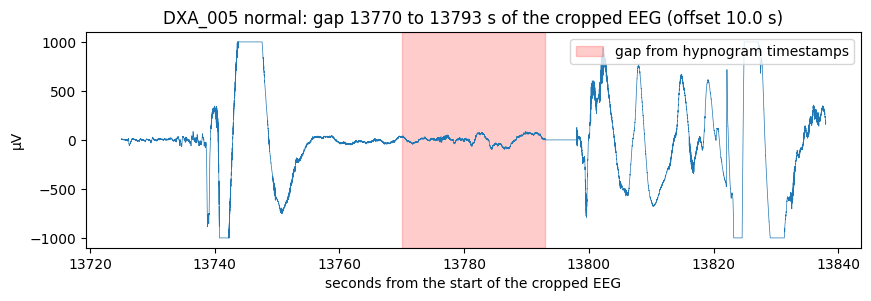

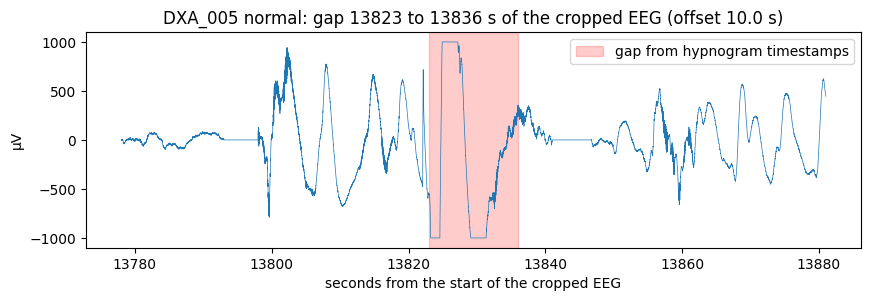

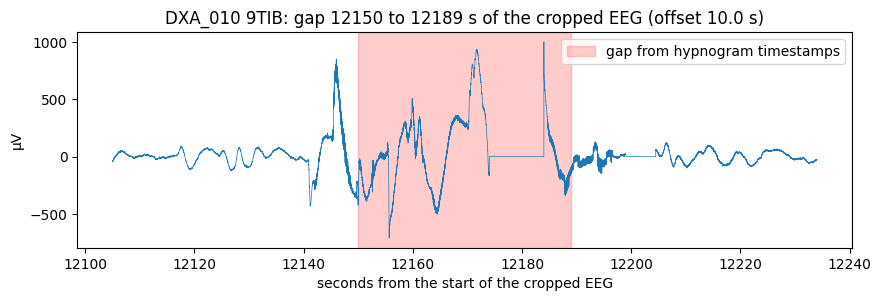

In [24]:
## CELL 5c: EEG around each documented gap (red band = gap predicted from the hypnogram timestamps)
def plot_gap(r, pad=45):
    raw = r.EDF_trim
    sf = raw.info["sfreq"]
    for g0, g1 in r.gaps:
        t0, t1 = max(g0 - pad, 0.0), min(g1 + pad, raw.n_times / sf)
        x = raw.get_data(picks=['EEG4'], start=int(t0 * sf), stop=int(t1 * sf), units="uV")[0]
        t = np.arange(len(x)) / sf + t0
        fig, ax = plt.subplots(figsize=(10, 2.8))
        ax.plot(t, x, lw=0.5)
        ax.axvspan(g0, g1, color="red", alpha=0.2, label="gap from hypnogram timestamps")
        ax.set_title(f"{r.subject_id} {r.condition}: gap {g0:.0f} to {g1:.0f} s of the cropped EEG (offset {r.offset_sec} s)")
        ax.set_xlabel("seconds from the start of the cropped EEG")
        ax.set_ylabel("µV")
        ax.legend(loc="upper right")
        plt.show()

for r in manifest_cleaned[manifest_cleaned["n_gaps"] > 0].itertuples():
    plot_gap(r)

In [25]:
## Create/view a "Gap table" (times as read in EDFBrowser, h:mm:ss from the start of the EDF)
def hms(sec):
    s = int(round(sec))
    return f"{s // 3600}:{(s % 3600) // 60:02d}:{s % 60:02d}"

gap_rows = []
for r in manifest_cleaned.itertuples():
    df = read_hypno_df(r.hyp_path)
    el = epoch_starts_edf(r.hyp_path)                 # includes the +10 s offset
    ep = df[EPOCH_COL].to_numpy()
    for k in range(r.i0, r.i1):
        step = el[k + 1] - el[k]
        if step > EPOCH_SEC + 0.5:
            gap_rows.append({
                "subject_id": r.subject_id, "condition": r.condition,
                "epoch_before": int(ep[k]), "epoch_after": int(ep[k + 1]),
                "before_ends_edfb": hms(el[k] + EPOCH_SEC),      # scored epoch before the gap ends here
                "after_starts_edfb": hms(el[k + 1]),             # next scored epoch begins here
                "gap_sec": step - EPOCH_SEC,
                "stage_before": int(df[STAGE_COL].iloc[k]), "stage_after": int(df[STAGE_COL].iloc[k + 1])})

## Shows only where gaps exist in EEG.edf files (when applicable). Somewhat redundant but good for verifying data integrity PRN.
gap_table = pd.DataFrame(gap_rows)
display(gap_table)

,subject_id,condition,epoch_before,epoch_after,before_ends_edfb,after_starts_edfb,gap_sec,stage_before,stage_after
0,DXA_005,normal,459,460,3:49:55,3:50:18,23.0,9,9
1,DXA_005,normal,460,461,3:50:48,3:51:01,13.0,9,9
2,DXA_010,9TIB,405,406,3:23:28,3:24:07,39.0,1,0


# Formatting Hypnograms

In [26]:
# hyp_raw = pd.read_csv(manifest.iloc[0]["hyp_path"])
# print(manifest.iloc[0][["subject_id", "condition"]].to_dict())
# print(hyp_raw.head(10))
# print(hyp_raw.dtypes)
# print(len(hyp_raw), "rows ->", round(len(hyp_raw) * 30 / 3600, 2), "hours at 30 s epochs")

In [27]:
## visually inspect first row hypnogram
## DXA_001 9TIB condition == 9.12 hours worth of hypnogram sleep data
hyp, raw_codes = load_hypno(manifest.iloc[0]["hyp_path"])
print(manifest.iloc[0][["subject_id", "condition"]].to_dict())
print(len(hyp), "epochs ->", round(len(hyp) * 0.5 / 60, 2), "hours")

hyp.sleep_statistics()        # dict of stats, durations in minutes
# hyp.plot_hypnogram()         # quick visual check of the staging

{'subject_id': 'DXA_001', 'condition': '9TIB'}
1095 epochs -> 9.12 hours


{'TIB': np.float64(547.5),
 'SPT': np.float64(544.0),
 'WASO': np.float64(14.5),
 'TST': np.float64(529.5),
 'SE': np.float64(96.7123),
 'SME': np.float64(97.3346),
 'SFI': np.float64(1.0765),
 'SOL': np.float64(3.0),
 'SOL_5min': np.float64(8.0),
 'Lat_REM': np.float64(59.5),
 'WAKE': np.float64(18.0),
 'N1': np.float64(32.5),
 'N2': np.float64(228.0),
 'N3': np.float64(127.0),
 'REM': np.float64(142.0),
 '%N1': np.float64(6.1379),
 '%N2': np.float64(43.0595),
 '%N3': np.float64(23.9849),
 '%REM': np.float64(26.8178)}

# Sleep Statistics

In [28]:
## CELL 6: Sleep statistics for every night (hypnogram window B-C)
rows, failed = [], []
for r in manifest_cleaned.itertuples():
    try:
        hyp, raw_codes = load_hypno(r.hyp_path, window=(r.i0, r.i1))   # epochs from B to C only
        stats = hyp.sleep_statistics()                                  # dict; durations in minutes

        counts = raw_codes.map(STAGE_MAP).value_counts()                # epochs per YASA stage label
        stage_counts = {f"n_{lab}_epochs": int(counts.get(lab, 0)) for lab in STAGE_MAP.values()}

        rows.append({"subject_id": r.subject_id, "condition": r.condition,
                     "n_epochs": len(hyp),
                     "n_gaps": r.n_gaps, "gap_total_sec": r.gap_total_sec,   # unscored gaps, not counted in TIB
                     **stats, **stage_counts})
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"{len(rows)} nights processed, {len(failed)} failed")
for f in failed[:10]:
    print(f)

if rows:
    sleep_statistics_df = pd.DataFrame(rows)
    sleep_statistics_df["condition"] = pd.Categorical(
        sleep_statistics_df["condition"], categories=["normal", "9TIB"])
    sleep_statistics_df = (sleep_statistics_df
                           .sort_values(["subject_id", "condition"])
                           .reset_index(drop=True))

    pd.set_option("display.max_columns", None)
    pd.set_option("display.width", 200)
    key_cols = ["subject_id", "condition", "n_epochs", "TIB", "SPT", "TST", "SE", "SOL", "WASO",
                "%N1", "%N2", "%N3", "%REM", "n_gaps", "gap_total_sec"]
    display(sleep_statistics_df[key_cols].round(1))

20 nights processed, 0 failed


,subject_id,condition,n_epochs,TIB,SPT,TST,SE,SOL,WASO,%N1,%N2,%N3,%REM,n_gaps,gap_total_sec
0,DXA_001,normal,1118,559.0,546.5,533.5,95.4,12.0,13.0,5.0,48.9,21.9,24.2,0,0.0
1,DXA_001,9TIB,1095,547.5,544.0,529.5,96.7,3.0,14.5,6.1,43.1,24.0,26.8,0,0.0
2,DXA_002,normal,825,412.5,400.5,371.5,90.1,11.5,27.0,8.9,29.7,45.2,16.2,0,0.0
3,DXA_002,9TIB,976,488.0,473.0,435.0,89.1,10.5,35.5,4.0,20.7,50.7,24.6,0,0.0
4,DXA_003,normal,596,298.0,296.0,283.5,95.1,1.5,12.5,6.9,33.0,36.3,23.8,0,0.0
5,DXA_003,9TIB,812,406.0,400.0,387.0,95.3,5.5,13.0,16.7,33.7,48.7,0.9,0,0.0
6,DXA_004,normal,697,348.5,338.0,330.5,94.8,10.0,7.0,5.6,38.4,27.1,28.9,0,0.0
7,DXA_004,9TIB,1119,559.5,555.5,509.0,91.0,3.5,46.5,5.9,39.1,18.0,37.0,0,0.0
8,DXA_005,normal,928,464.0,462.0,425.5,91.7,1.5,26.5,17.2,28.1,47.0,7.8,2,36.0
9,DXA_005,9TIB,1083,541.5,515.5,480.0,88.6,25.0,34.0,7.4,33.5,32.7,26.4,0,0.0


In [29]:
## Show sleep statistics
sleep_statistics_df.head()

,subject_id,condition,n_epochs,n_gaps,gap_total_sec,TIB,SPT,WASO,TST,SE,SME,SFI,SOL,SOL_5min,Lat_REM,WAKE,N1,N2,N3,REM,%N1,%N2,%N3,%REM,n_WAKE_epochs,n_N1_epochs,n_N2_epochs,n_N3_epochs,n_REM_epochs,n_UNS_epochs,UNS
0,DXA_001,normal,1118,0,0.0,559.0,546.5,13.0,533.5,95.4383,97.6212,1.0122,12.0,12.0,150.5,25.5,26.5,261.0,117.0,129.0,4.9672,48.9222,21.9306,24.1799,51,53,522,234,258,0,NaN
1,DXA_001,9TIB,1095,0,0.0,547.5,544.0,14.5,529.5,96.7123,97.3346,1.0765,3.0,8.0,59.5,18.0,32.5,228.0,127.0,142.0,6.1379,43.0595,23.9849,26.8178,36,65,456,254,284,0,NaN
2,DXA_002,normal,825,0,0.0,412.5,400.5,27.0,371.5,90.0606,92.7591,2.7456,11.5,11.5,109.0,39.0,33.0,110.5,168.0,60.0,8.8829,29.7443,45.2221,16.1507,78,66,221,336,120,4,2.0
3,DXA_002,9TIB,976,0,0.0,488.0,473.0,35.5,435.0,89.1393,91.9662,2.4138,10.5,10.5,114.5,49.5,17.5,90.0,220.5,107.0,4.0230,20.6897,50.6897,24.5977,99,35,180,441,214,7,3.5
4,DXA_003,normal,596,0,0.0,298.0,296.0,12.5,283.5,95.1342,95.7770,1.5873,1.5,1.5,49.5,14.5,19.5,93.5,103.0,67.5,6.8783,32.9806,36.3316,23.8095,29,39,187,206,135,0,NaN


In [30]:
# TIB should equal the number of epochs x 30 s (in minutes) on every night
print("max |TIB - n_epochs*0.5|:", (sleep_statistics_df["TIB"] - sleep_statistics_df["n_epochs"] * 0.5).abs().max())

# TIB + gap time should match the cropped EEG length
chk = sleep_statistics_df.merge(manifest_cleaned[["subject_id", "condition", "dur_min"]], on=["subject_id", "condition"])
print("max |TIB + gaps - EEG length| (min):",
      (chk["TIB"] + chk["gap_total_sec"] / 60 - chk["dur_min"]).abs().max())

# TIB by condition: 9TIB nights should sit near 540 min
print(sleep_statistics_df.groupby("condition", observed=True)["TIB"].describe().round(1))

max |TIB - n_epochs*0.5|: 0.0
max |TIB + gaps - EEG length| (min): 0.0
           count   mean   std    min    25%    50%    75%    max
condition                                                       
normal      10.0  407.7  76.5  298.0  358.5  404.8  451.6  559.0
9TIB        10.0  524.1  45.6  406.0  533.9  540.8  546.0  559.5


# Sleep Spindles Detection

In [31]:
## Spindle detection on the cropped EEG4 channel
INCLUDE = (1,2,3,4)
STAGE_NAMES = {1: "N1", 2: "N2", 3: "N3", 4: "REM"}

def tag(df, subject_id, condition):
    df = df.reset_index(drop=True).copy()
    df.insert(0, "condition", condition)
    df.insert(0, "subject_id", subject_id)
    return df

def hypno_to_samples_timed(hyp, el_win, tmin, n_samples, sf):
    """One stage value per EEG sample, placed by each epoch's start time. Uncovered time (gaps) stays -2 = unscored."""
    out = np.full(n_samples, -2, dtype=int)
    n = int(round(EPOCH_SEC * sf))
    for s, t in zip(hyp.as_int().to_numpy(), el_win):
        a = int(round((t - tmin) * sf))
        if 0 <= a < n_samples:
            out[a:min(a + n, n_samples)] = s
    return out

def detect_spindles_night(raw, hyp, el_win, subject_id, condition):
    sf = raw.info["sfreq"]
    data = raw.get_data(picks=EEG_CH, units="uV") ## (1, n_samples), microvolts
    tmin = max(el_win[0], 0.0)                               # same start time the crop used
    hyp_up = hypno_to_samples_timed(hyp, el_win, tmin, data.shape[1], sf)

    sp = yasa.spindles_detect(data, sf, ch_names=[EEG_CH], hypno=hyp_up,
                              include=INCLUDE, verbose=False)   

    if sp is None: ## YASA returns None if nothing is detected
        events, by_stage = pd.DataFrame(), pd.DataFrame()
    else:
        events = sp.summary() ## one row per spindle
        by_stage = sp.summary(grp_chan=True, grp_stage=True).reset_index() ## one row per stage
        for df in (events, by_stage):
            df["Stage"] = df["Stage"].map(STAGE_NAMES)

    meta = {"subject_id": subject_id, "condition": condition, "sf": sf,
            "eeg_min": round(data.shape[1] / sf / 60, 2),
            "hypno_min": round(len(hyp) * EPOCH_SEC / 60, 2),
            "eeg_minus_epochs_sec": round(data.shape[1] / sf - len(hyp) * EPOCH_SEC, 1), ## equals the gap time
            "n_gaps": len(find_gaps(el_win, tmin)), "n_spindles": len(events)}
    return tag(events, subject_id, condition), tag(by_stage, subject_id, condition), meta

events_list, stage_list, meta_list, failed = [], [], [], []
for r in manifest_cleaned.itertuples():
    try:
        hyp, _ = load_hypno(r.hyp_path, window=(r.i0, r.i1))
        el_win = epoch_starts_edf(r.hyp_path)[r.i0:r.i1 + 1]     # epoch starts on the EDF axis (includes the 10 s offset)
        events, by_stage, meta = detect_spindles_night(r.EDF_trim, hyp, el_win, r.subject_id, r.condition)
        events_list.append(events); stage_list.append(by_stage); meta_list.append(meta)
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"{len(meta_list)} nights processed, {len(failed)} failed")
for f in failed[:10]:
    print(f)

if meta_list:
    spindle_events_df   = pd.concat(events_list, ignore_index=True)   # one row per spindle, all nights
    spindle_by_stage_df = pd.concat(stage_list, ignore_index=True)    # one row per night x stage
    spindle_meta_df     = pd.DataFrame(meta_list)
    for df in (spindle_events_df, spindle_by_stage_df, spindle_meta_df):
        df["condition"] = pd.Categorical(df["condition"], categories=["normal", "9TIB"])
    # display(spindle_meta_df)
    # display(spindle_by_stage_df.round(2).head(10))

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]

20 nights processed, 0 failed


In [32]:
spindle_events_df.head().round(2) ## each row is an identified sleep sindle

,subject_id,condition,Start,Peak,End,Duration,Amplitude,AmpFiltered,RMS,AbsPower,RelPower,Frequency,Oscillations,Symmetry,Stage,Channel,IdxChannel
0,DXA_001,9TIB,838.76,839.26,839.66,0.91,46.94,35.01,8.84,1.93,0.72,12.73,12.0,0.55,N1,EEG4,0
1,DXA_001,9TIB,915.97,916.30,916.66,0.68,26.47,23.56,6.72,1.73,0.40,13.02,8.0,0.47,N2,EEG4,0
2,DXA_001,9TIB,947.95,948.75,948.85,0.91,44.49,24.84,7.93,1.64,0.38,13.00,12.0,0.89,N2,EEG4,0
3,DXA_001,9TIB,952.55,953.12,953.70,1.15,51.21,38.50,10.56,2.17,0.70,12.62,15.0,0.49,N2,EEG4,0
4,DXA_001,9TIB,968.94,969.32,969.73,0.79,40.32,29.68,8.43,1.86,0.56,12.78,10.0,0.49,N2,EEG4,0


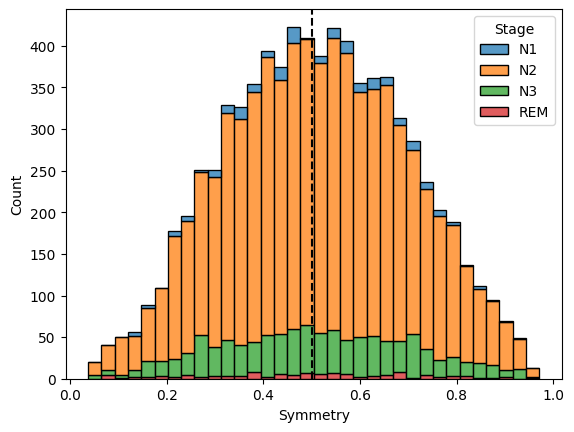

In [33]:
sns.histplot(data=spindle_events_df, x='Symmetry', hue='Stage', multiple='stack', )
## symmetry should be close to 0.5, indicating most prominent spindle peak occurs mid-way through detected spindle
plt.axvline(x=0.5, ymin=0, ymax=1, lw='1.5', ls='--', color='black')
plt.show()

In [34]:
spindle_events_df.shape

(7845, 17)

In [35]:
# spindle_events_df.to_csv('spindle_events_df_11.17.26.csv')

In [36]:
spindle_by_stage_df.head().round(2)

,subject_id,condition,Stage,Channel,Count,Density,Duration,Amplitude,AmpFiltered,RMS,AbsPower,RelPower,Frequency,Oscillations,Symmetry
0,DXA_001,9TIB,N1,EEG4,10,0.31,0.76,32.81,20.89,7.19,1.70,0.43,12.70,9.30,0.43
1,DXA_001,9TIB,N2,EEG4,908,3.98,0.84,30.74,18.58,6.56,1.57,0.39,12.69,10.16,0.52
2,DXA_001,9TIB,N3,EEG4,46,0.36,0.71,34.37,20.41,7.52,1.74,0.35,12.67,8.52,0.47
3,DXA_001,9TIB,REM,EEG4,12,0.08,0.66,24.03,12.60,5.08,1.42,0.33,12.51,7.75,0.49
4,DXA_001,normal,N1,EEG4,11,0.42,0.72,27.80,16.63,5.80,1.49,0.38,12.64,8.45,0.39


In [37]:
spindle_by_stage_df.shape

(71, 15)

In [38]:
# spindle_by_stage_df.to_csv('spindle_by_stage_df_11.17.26.csv')

In [39]:
spindle_meta_df.head()

,subject_id,condition,sf,eeg_min,hypno_min,eeg_minus_epochs_sec,n_gaps,n_spindles
0,DXA_001,9TIB,256.0,547.5,547.5,0.0,0,976
1,DXA_001,normal,256.0,559.0,559.0,0.0,0,1176
2,DXA_002,9TIB,256.0,488.0,488.0,0.0,0,71
3,DXA_002,normal,256.0,412.5,412.5,0.0,0,94
4,DXA_003,9TIB,256.0,406.0,406.0,0.0,0,76


In [40]:
spindle_meta_df.shape

(20, 8)

In [41]:
# asfasfasfasdf
## stop here before old code

# Predicting Sleep Stages

In [42]:
DXA_demo_df.head()
## just a check in that this is here as we move into sleep staging.

,subject_id,age,alcohol,cannabis,sex
0,DXA_001,19,0.0,0.0,Female
1,DXA_002,18,0.0,0.0,Male
2,DXA_003,19,1.0,0.0,Male
3,DXA_004,23,1.0,0.0,Male
4,DXA_005,20,1.0,0.0,Male


In [43]:
DXA_demo_sleep_stats_df = pd.merge(DXA_demo_df, sleep_statistics_df, how = 'inner', left_on=['subject_id'], right_on = 'subject_id')

DXA_demo_sleep_stats_df.head(20)

,subject_id,age,alcohol,cannabis,sex,condition,n_epochs,n_gaps,gap_total_sec,TIB,SPT,WASO,TST,SE,SME,SFI,SOL,SOL_5min,Lat_REM,WAKE,N1,N2,N3,REM,%N1,%N2,%N3,%REM,n_WAKE_epochs,n_N1_epochs,n_N2_epochs,n_N3_epochs,n_REM_epochs,n_UNS_epochs,UNS
0,DXA_001,19,0.0,0.0,Female,normal,1118,0,0.0,559.0,546.5,13.0,533.5,95.4383,97.6212,1.0122,12.0,12.0,150.5,25.5,26.5,261.0,117.0,129.0,4.9672,48.9222,21.9306,24.1799,51,53,522,234,258,0,NaN
1,DXA_001,19,0.0,0.0,Female,9TIB,1095,0,0.0,547.5,544.0,14.5,529.5,96.7123,97.3346,1.0765,3.0,8.0,59.5,18.0,32.5,228.0,127.0,142.0,6.1379,43.0595,23.9849,26.8178,36,65,456,254,284,0,NaN
2,DXA_002,18,0.0,0.0,Male,normal,825,0,0.0,412.5,400.5,27.0,371.5,90.0606,92.7591,2.7456,11.5,11.5,109.0,39.0,33.0,110.5,168.0,60.0,8.8829,29.7443,45.2221,16.1507,78,66,221,336,120,4,2.0
3,DXA_002,18,0.0,0.0,Male,9TIB,976,0,0.0,488.0,473.0,35.5,435.0,89.1393,91.9662,2.4138,10.5,10.5,114.5,49.5,17.5,90.0,220.5,107.0,4.0230,20.6897,50.6897,24.5977,99,35,180,441,214,7,3.5
4,DXA_003,19,1.0,0.0,Male,normal,596,0,0.0,298.0,296.0,12.5,283.5,95.1342,95.7770,1.5873,1.5,1.5,49.5,14.5,19.5,93.5,103.0,67.5,6.8783,32.9806,36.3316,23.8095,29,39,187,206,135,0,NaN
5,DXA_003,19,1.0,0.0,Male,9TIB,812,0,0.0,406.0,400.0,13.0,387.0,95.3202,96.7500,1.7829,5.5,5.5,372.5,19.0,64.5,130.5,188.5,3.5,16.6667,33.7209,48.7080,0.9044,38,129,261,377,7,0,NaN
6,DXA_004,23,1.0,0.0,Male,normal,697,0,0.0,348.5,338.0,7.0,330.5,94.8350,97.7811,0.9077,10.0,10.0,61.0,17.5,18.5,127.0,89.5,95.5,5.5976,38.4266,27.0802,28.8956,35,37,254,179,191,1,0.5
7,DXA_004,23,1.0,0.0,Male,9TIB,1119,0,0.0,559.5,555.5,46.5,509.0,90.9741,91.6292,2.0629,3.5,46.5,109.0,50.5,30.0,199.0,91.5,188.5,5.8939,39.0963,17.9764,37.0334,101,60,398,183,377,0,NaN
8,DXA_005,20,1.0,0.0,Male,normal,928,2,36.0,464.0,462.0,26.5,425.5,91.7026,92.0996,2.2562,1.5,1.5,144.0,28.5,73.0,119.5,200.0,33.0,17.1563,28.0846,47.0035,7.7556,57,146,239,400,66,20,10.0
9,DXA_005,20,1.0,0.0,Male,9TIB,1083,0,0.0,541.5,515.5,34.0,480.0,88.6427,93.1135,1.6875,25.0,25.0,76.5,60.0,35.5,161.0,157.0,126.5,7.3958,33.5417,32.7083,26.3542,120,71,322,314,253,3,1.5


In [44]:
sleep_statistics_df.head()

,subject_id,condition,n_epochs,n_gaps,gap_total_sec,TIB,SPT,WASO,TST,SE,SME,SFI,SOL,SOL_5min,Lat_REM,WAKE,N1,N2,N3,REM,%N1,%N2,%N3,%REM,n_WAKE_epochs,n_N1_epochs,n_N2_epochs,n_N3_epochs,n_REM_epochs,n_UNS_epochs,UNS
0,DXA_001,normal,1118,0,0.0,559.0,546.5,13.0,533.5,95.4383,97.6212,1.0122,12.0,12.0,150.5,25.5,26.5,261.0,117.0,129.0,4.9672,48.9222,21.9306,24.1799,51,53,522,234,258,0,NaN
1,DXA_001,9TIB,1095,0,0.0,547.5,544.0,14.5,529.5,96.7123,97.3346,1.0765,3.0,8.0,59.5,18.0,32.5,228.0,127.0,142.0,6.1379,43.0595,23.9849,26.8178,36,65,456,254,284,0,NaN
2,DXA_002,normal,825,0,0.0,412.5,400.5,27.0,371.5,90.0606,92.7591,2.7456,11.5,11.5,109.0,39.0,33.0,110.5,168.0,60.0,8.8829,29.7443,45.2221,16.1507,78,66,221,336,120,4,2.0
3,DXA_002,9TIB,976,0,0.0,488.0,473.0,35.5,435.0,89.1393,91.9662,2.4138,10.5,10.5,114.5,49.5,17.5,90.0,220.5,107.0,4.0230,20.6897,50.6897,24.5977,99,35,180,441,214,7,3.5
4,DXA_003,normal,596,0,0.0,298.0,296.0,12.5,283.5,95.1342,95.7770,1.5873,1.5,1.5,49.5,14.5,19.5,93.5,103.0,67.5,6.8783,32.9806,36.3316,23.8095,29,39,187,206,135,0,NaN


In [45]:
show(manifest_cleaned_df) ## has EEG, hypnogram, and demographic data within

,subject_id,condition,edf_path,hyp_path,i0,i1,offset_sec,tmin_sec,tmax_sec,dur_min,n_epochs,n_gaps,gap_total_sec,gaps,dur_diff_ex_gaps_sec,end_clipped_sec,n_overlaps,n_invalid_inside,end_is_wake,age,alcohol,cannabis,sex
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1094,10.0,25.0,32875.0,547.50,1095,0,0.0,[],0.0,0.0,0,0,True,19,0.0,0.0,Female
1,DXA_001,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1117,10.0,26.0,33566.0,559.00,1118,0,0.0,[],0.0,0.0,0,0,True,19,0.0,0.0,Female
2,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,2,977,10.0,85.0,29365.0,488.00,976,0,0.0,[],0.0,0.0,0,7,True,18,0.0,0.0,Male
3,DXA_002,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,21,845,10.0,655.0,25405.0,412.50,825,0,0.0,[],0.0,0.0,0,4,True,18,0.0,0.0,Male
4,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,811,10.0,59.0,24419.0,406.00,812,0,0.0,[],0.0,0.0,0,0,True,19,1.0,0.0,Male
5,DXA_003,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,1,596,10.0,55.0,17935.0,298.00,596,0,0.0,[],0.0,0.0,0,0,True,19,1.0,0.0,Male
6,DXA_004,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1118,10.0,25.0,33595.0,559.50,1119,0,0.0,[],0.0,0.0,0,0,True,23,1.0,0.0,Male
7,DXA_004,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,696,10.0,26.0,20936.0,348.50,697,0,0.0,[],0.0,0.0,0,1,True,23,1.0,0.0,Male
8,DXA_005,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1082,10.0,25.0,32515.0,541.50,1083,0,0.0,[],0.0,0.0,0,3,True,20,1.0,0.0,Male
9,DXA_005,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,927,10.0,25.0,27901.0,464.60,928,2,36.0,"[(13770.0, 13793.0), (13823.0, 13836.0)]",0.0,0.0,0,20,True,20,1.0,0.0,Male


In [46]:
## Isolate 9-h TIB conditions for current data analysis
manifest_cleaned_9TIB = manifest_cleaned_df[manifest_cleaned_df["condition"] == "9TIB"]
manifest_cleaned_9TIB = manifest_cleaned_9TIB[manifest_cleaned_9TIB['n_gaps']<1].copy().reset_index(drop=True) ## drop instances (rows) where there are gaps of data, until resolved. 

print(f"{len(manifest_cleaned_9TIB)} nights, {manifest_cleaned_9TIB['subject_id'].nunique()} participants")
show(manifest_cleaned_9TIB)

9 nights, 9 participants


,subject_id,condition,edf_path,hyp_path,i0,i1,offset_sec,tmin_sec,tmax_sec,dur_min,n_epochs,n_gaps,gap_total_sec,gaps,dur_diff_ex_gaps_sec,end_clipped_sec,n_overlaps,n_invalid_inside,end_is_wake,age,alcohol,cannabis,sex
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1094,10.0,25.0,32875.0,547.5,1095,0,0.0,[],0.0,0.0,0,0,True,19,0.0,0.0,Female
1,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,2,977,10.0,85.0,29365.0,488.0,976,0,0.0,[],0.0,0.0,0,7,True,18,0.0,0.0,Male
2,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,811,10.0,59.0,24419.0,406.0,812,0,0.0,[],0.0,0.0,0,0,True,19,1.0,0.0,Male
3,DXA_004,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1118,10.0,25.0,33595.0,559.5,1119,0,0.0,[],0.0,0.0,0,0,True,23,1.0,0.0,Male
4,DXA_005,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1082,10.0,25.0,32515.0,541.5,1083,0,0.0,[],0.0,0.0,0,3,True,20,1.0,0.0,Male
5,DXA_008,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1079,10.0,26.0,32426.0,540.0,1080,0,0.0,[],0.0,0.0,0,0,True,21,0.0,0.0,Female
6,DXA_011,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1094,10.0,25.0,32875.0,547.5,1095,0,0.0,[],0.0,0.0,0,0,True,21,1.0,0.0,Female
7,DXA_013,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1082,10.0,25.0,32515.0,541.5,1083,0,0.0,[],0.0,0.0,0,0,True,24,1.0,0.0,Female
8,DXA_014,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,0,1072,10.0,26.0,32216.0,536.5,1073,0,0.0,[],0.0,0.0,0,61,True,19,0.0,0.0,Female


In [47]:
## Aggregate SleepStaging metadata: age and sex
def row_metadata(r):
    """{'age': years, 'male': True/False} for yasa.SleepStaging, or None if age is missing or sex is not Female/Male."""
    age = pd.to_numeric(r.age, errors="coerce")
    if pd.isna(age) or r.sex not in ("Female", "Male"):
        return None
    return {"age": float(age), "male": r.sex == "Male"}

chk = manifest_cleaned_9TIB[["subject_id", "age", "sex"]].copy()
chk["metadata"] = [row_metadata(r) for r in manifest_cleaned_9TIB.itertuples()]
display(chk)
print("Nights with no usable metadata:", int(chk["metadata"].isna().sum()))

,subject_id,age,sex,metadata
0,DXA_001,19,Female,"{'age': 19.0, 'male': False}"
1,DXA_002,18,Male,"{'age': 18.0, 'male': True}"
2,DXA_003,19,Male,"{'age': 19.0, 'male': True}"
3,DXA_004,23,Male,"{'age': 23.0, 'male': True}"
4,DXA_005,20,Male,"{'age': 20.0, 'male': True}"
5,DXA_008,21,Female,"{'age': 21.0, 'male': False}"
6,DXA_011,21,Female,"{'age': 21.0, 'male': False}"
7,DXA_013,24,Female,"{'age': 24.0, 'male': False}"
8,DXA_014,19,Female,"{'age': 19.0, 'male': False}"


Nights with no usable metadata: 0


### Code for YASA.SleepStaging

raw = mne.io.read_raw_edf("myfile.edf", preload=True)
sls = yasa.SleepStaging(
    raw,
    eeg_name="C4-M1",
    eog_name="LOC-M2",
    emg_name="EMG1-EMG2",
    metadata=dict(age=29, male=True),
)

**Predict hypnogram (returns a yasa.Hypnogram object since v0.7)** 
hyp = sls.predict()

**DataFrame of stage probabilities per 30-sec epoch** 
proba = hyp.proba

**Or call predict_proba() directly (supports a custom joblib LGBMClassifier path or "auto")** 
proba_direct = sls.predict_proba(path_to_model="auto")

**Per-epoch prediction confidence (maximum probability across stages)** 
confidence = proba.max(axis=1)

In [ ]:
import time
import warnings
import sklearn
from sklearn.metrics import cohen_kappa_score
from sklearn.exceptions import InconsistentVersionWarning

## YASA's bundled model files were saved with an old scikit-learn; this hides that message after you have seen it
warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
print(f"yasa {yasa.__version__} | scikit-learn {sklearn.__version__} | mne {mne.__version__}")

In [64]:
YASA_LABEL_MAP = {"W": "WAKE", "WAKE": "WAKE", "N1": "N1", "N2": "N2", "N3": "N3", "R": "REM", "REM": "REM"}
STAGES5 = ["WAKE", "N1", "N2", "N3", "REM"]

def stage_recording(raw, metadata=None, eeg_ch=EEG_CH, eog_ch=LEOG_CH):
    """yasa.SleepStaging on one cropped recording. Inputs: the samples and age/sex. Nothing from the hypnogram."""
    if not isinstance(raw, mne.io.BaseRaw):               # unwrap a RawBox, if you use one
        raw = raw.raw
    chans = [eeg_ch] + ([eog_ch] if eog_ch is not None else [])
    rec = raw.copy().pick(chans)                          # EEG (+ EOG) only; a copy, so EDF_trim is never altered
    proba = yasa.SleepStaging(rec, eeg_name=eeg_ch, eog_name=eog_ch, metadata=metadata).predict().proba
    if not np.allclose(proba.sum(axis=1), 1.0, atol=1e-3):
        raise ValueError("probabilities do not sum to 1")
    proba = proba.rename(columns=lambda c: YASA_LABEL_MAP[str(c).upper()])[STAGES5]

    n = len(proba)
    idx = np.arange(n)
    out = pd.DataFrame({
        "yasa_epoch": idx,                                          # 0-based epoch number within the cropped recording
        "yasa_trim_sec": idx * EPOCH_SEC,                           # epoch start, seconds from the first sample of EDF_trim
        "yasa_edf_sec": rec.first_time + idx * EPOCH_SEC,           # epoch start, seconds from the start of the original EDF
        "yasa": proba.idxmax(axis=1).to_numpy(),
        "yasa_confidence": proba.max(axis=1).to_numpy()})
    out["yasa_edf_hms"] = [hms(x) for x in out["yasa_edf_sec"]]
    for s in STAGES5:
        out[f"p_{s}"] = proba[s].to_numpy()                         # YASA's probability for each stage
    leftover = rec.n_times / rec.info["sfreq"] - n * EPOCH_SEC      # seconds at the end that do not fill an epoch
    return out, leftover

In [65]:
## CELL 24 | Staging input: only what SleepStaging needs
assert (manifest_cleaned_9TIB["n_gaps"] == 0).all(), "gap nights need segment-wise staging, which uses hypnogram times"
stage_in = manifest_cleaned_9TIB[["subject_id", "condition", "age", "sex", "EDF_trim"]].reset_index(drop=True)
print(stage_in.columns.tolist())          # no hyp_path, i0, i1 or any other hypnogram-derived column
print(f"{len(stage_in)} nights to stage")

['subject_id', 'condition', 'age', 'sex', 'EDF_trim']
9 nights to stage


In [66]:
## CELL 25 | Test one night, hypnogram-free (and check that the EOG channel changes the result)
r = next(stage_in.itertuples())
meta = row_metadata(r)
print(f"{r.subject_id} {r.condition} | metadata: {meta} | channels in EDF_trim: {r.EDF_trim.ch_names}")

t0 = time.time()
out, leftover = stage_recording(r.EDF_trim, metadata=meta)
print(f"staged {len(out)} epochs in {time.time() - t0:.0f} s | mean confidence {out['yasa_confidence'].mean():.2f} "
      f"| {leftover:.1f} s left over at the end")
print(out["yasa"].value_counts().reindex(STAGES5).fillna(0).astype(int))

out_noeog, _ = stage_recording(r.EDF_trim, metadata=meta, eog_ch=None)
print("epochs whose YASA stage changed when the LEOG was added:", int((out["yasa"] != out_noeog["yasa"]).sum()), "of", len(out))

DXA_001 9TIB | metadata: {'age': 19.0, 'male': False} | channels in EDF_trim: ['EEG4', 'EEG3', 'EEG2']
staged 1095 epochs in 1 s | mean confidence 0.79 | 0.0 s left over at the end
yasa
WAKE     73
N1       93
N2      527
N3      175
REM     227
Name: count, dtype: int64
epochs whose YASA stage changed when the LEOG was added: 124 of 1095


In [67]:
## CELL 26 | Stage all nights (YASA table only)
yasa_list, failed = [], []
for r in stage_in.itertuples():
    try:
        t0 = time.time()
        meta = row_metadata(r)
        out, leftover = stage_recording(r.EDF_trim, metadata=meta)
        out.insert(0, "condition", r.condition)
        out.insert(0, "subject_id", r.subject_id)
        out["used_metadata"] = meta is not None
        out["used_eog"] = LEOG_CH is not None
        yasa_list.append(out)
        print(f"{r.subject_id}: {len(out)} epochs, {leftover:.1f} s left over, {time.time() - t0:.0f} s")
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"\n{len(yasa_list)} nights staged, {len(failed)} failed")
for f in failed[:10]:
    print(f)
if yasa_list:
    yasa_9TIB = pd.concat(yasa_list, ignore_index=True)     # one row per YASA epoch
    print("Nights staged without metadata:", sorted(yasa_9TIB.loc[~yasa_9TIB["used_metadata"], "subject_id"].unique()))

DXA_001: 1095 epochs, 0.0 s left over, 1 s
DXA_002: 976 epochs, 0.0 s left over, 1 s
DXA_003: 812 epochs, 0.0 s left over, 1 s
DXA_004: 1119 epochs, 0.0 s left over, 1 s
DXA_005: 1083 epochs, 0.0 s left over, 1 s
DXA_008: 1080 epochs, 0.0 s left over, 1 s
DXA_011: 1095 epochs, 0.0 s left over, 1 s
DXA_013: 1083 epochs, 0.0 s left over, 1 s
DXA_014: 1073 epochs, 0.0 s left over, 1 s

9 nights staged, 0 failed
Nights staged without metadata: []


In [68]:
## CELL 27 | Sleep Profiler table, built now from the hypnogram files
sp_list = []
for r in manifest_cleaned_9TIB.itertuples():
    d = read_hypno_df(r.hyp_path)
    _, codes = load_hypno(r.hyp_path, window=(r.i0, r.i1))          # codes after the NRH rule, inside B-C
    out = epoch_timestamps(r.hyp_path, r.i0, r.i1)                  # epoch, sp_* and eeg_* timestamps (Cell 25a)
    out.insert(0, "condition", r.condition)
    out.insert(0, "subject_id", r.subject_id)
    out["sp_stage_final"] = d[STAGE_COL].to_numpy()[r.i0:r.i1 + 1]
    out["sp_resolved_code"] = codes.to_numpy()
    out["sleep_profiler"] = codes.map(STAGE_MAP).to_numpy()
    sp_list.append(out)
sp_9TIB = pd.concat(sp_list, ignore_index=True)
print(f"{len(sp_9TIB)} Sleep Profiler epochs")

9416 Sleep Profiler epochs


/var/folders/7d/370678cs0jzdr2slyl3k7m2w0000gn/T/ipykernel_96629/1973691130.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sp_dt = pd.to_datetime(df[DATE_COL].astype(str).str.strip() + " " + df[CLOCK_COL].astype(str).str.strip(),


In [71]:
sp_9TIB.columns

Index(['subject_id', 'condition', 'epoch', 'sp_elapsed_sec', 'sp_clock', 'sp_datetime', 'eeg_edf_sec', 'eeg_edf_hms', 'eeg_trim_sec', 'eeg_clock', 'sp_stage_final', 'sp_resolved_code',
       'sleep_profiler', 'trim_sec'],
      dtype='object')

In [72]:
sp_9TIB.head()

,subject_id,condition,epoch,sp_elapsed_sec,sp_clock,sp_datetime,eeg_edf_sec,eeg_edf_hms,eeg_trim_sec,eeg_clock,sp_stage_final,sp_resolved_code,sleep_profiler,trim_sec
0,DXA_001,9TIB,1,15.0,23:08:18,2019-10-07 23:08:18,25.0,0:00:25,0.0,23:08:18,0,0,WAKE,0
1,DXA_001,9TIB,2,45.0,23:08:48,2019-10-07 23:08:48,55.0,0:00:55,30.0,23:08:48,0,0,WAKE,30
2,DXA_001,9TIB,3,75.0,23:09:18,2019-10-07 23:09:18,85.0,0:01:25,60.0,23:09:18,0,0,WAKE,60
3,DXA_001,9TIB,4,105.0,23:09:48,2019-10-07 23:09:48,115.0,0:01:55,90.0,23:09:48,0,0,WAKE,90
4,DXA_001,9TIB,5,135.0,23:10:18,2019-10-07 23:10:18,145.0,0:02:25,120.0,23:10:18,0,0,WAKE,120


In [69]:
## CELL 28 | Join YASA and Sleep Profiler on time (not on row order) and check the alignment
sp_9TIB["trim_sec"] = sp_9TIB["eeg_trim_sec"].round().astype(int)             # epoch start in the cropped EEG, from the hypnogram
yasa_9TIB["trim_sec"] = yasa_9TIB["yasa_trim_sec"].round().astype(int)        # epoch start in the cropped EEG, from YASA's own grid

m = sp_9TIB.merge(yasa_9TIB, on=["subject_id", "condition", "trim_sec"], how="outer", indicator=True)
print(m["_merge"].value_counts())
unmatched = m[m["_merge"] != "both"].groupby(["subject_id", "condition", "_merge"], observed=True).size()
print("epochs found on only one side (should be empty):")
print(unmatched)

m["edf_time_diff_sec"] = m["yasa_edf_sec"] - m["eeg_edf_sec"]               # both are times on the original EDF axis
print("max |YASA epoch start - hypnogram epoch start| on the EDF axis (s):", m["edf_time_diff_sec"].abs().max())

both = m["_merge"] == "both"
m["agree"] = np.where(both & (m["sleep_profiler"] != "UNS"), (m["sleep_profiler"] == m["yasa"]).astype(float), np.nan)

cols = ["subject_id", "condition", "epoch", "sp_elapsed_sec", "sp_clock", "sp_datetime",
        "eeg_edf_sec", "eeg_edf_hms", "eeg_trim_sec", "yasa_epoch", "yasa_edf_sec", "yasa_edf_hms", "edf_time_diff_sec",
        "sp_stage_final", "sp_resolved_code", "sleep_profiler", "yasa", "yasa_confidence",
        "p_WAKE", "p_N1", "p_N2", "p_N3", "p_REM", "agree", "used_metadata", "used_eog"]
epoch_pairs_9TIB = m[cols].sort_values(["subject_id", "condition", "eeg_trim_sec"]).reset_index(drop=True)
display(epoch_pairs_9TIB.head(10))

_merge
both          9416
left_only        0
right_only       0
Name: count, dtype: int64
epochs found on only one side (should be empty):
Series([], dtype: int64)
max |YASA epoch start - hypnogram epoch start| on the EDF axis (s): 0.0


,subject_id,condition,epoch,sp_elapsed_sec,sp_clock,sp_datetime,eeg_edf_sec,eeg_edf_hms,eeg_trim_sec,yasa_epoch,yasa_edf_sec,yasa_edf_hms,edf_time_diff_sec,sp_stage_final,sp_resolved_code,sleep_profiler,yasa,yasa_confidence,p_WAKE,p_N1,p_N2,p_N3,p_REM,agree,used_metadata,used_eog
0,DXA_001,9TIB,1,15.0,23:08:18,2019-10-07 23:08:18,25.0,0:00:25,0.0,0,25.0,0:00:25,0.0,0,0,WAKE,WAKE,0.999435,0.999435,0.000323,0.000185,0.000057,3.401412e-07,1.0,True,True
1,DXA_001,9TIB,2,45.0,23:08:48,2019-10-07 23:08:48,55.0,0:00:55,30.0,1,55.0,0:00:55,0.0,0,0,WAKE,WAKE,0.999840,0.999840,0.000034,0.000032,0.000091,3.610343e-06,1.0,True,True
2,DXA_001,9TIB,3,75.0,23:09:18,2019-10-07 23:09:18,85.0,0:01:25,60.0,2,85.0,0:01:25,0.0,0,0,WAKE,WAKE,0.999736,0.999736,0.000089,0.000058,0.000113,4.185555e-06,1.0,True,True
3,DXA_001,9TIB,4,105.0,23:09:48,2019-10-07 23:09:48,115.0,0:01:55,90.0,3,115.0,0:01:55,0.0,0,0,WAKE,WAKE,0.999142,0.999142,0.000396,0.000400,0.000060,1.519592e-06,1.0,True,True
4,DXA_001,9TIB,5,135.0,23:10:18,2019-10-07 23:10:18,145.0,0:02:25,120.0,4,145.0,0:02:25,0.0,0,0,WAKE,WAKE,0.995927,0.995927,0.002453,0.001250,0.000363,8.005419e-06,1.0,True,True
5,DXA_001,9TIB,6,165.0,23:10:48,2019-10-07 23:10:48,175.0,0:02:55,150.0,5,175.0,0:02:55,0.0,0,0,WAKE,WAKE,0.998926,0.998926,0.000607,0.000196,0.000266,4.354384e-06,1.0,True,True
6,DXA_001,9TIB,7,195.0,23:11:18,2019-10-07 23:11:18,205.0,0:03:25,180.0,6,205.0,0:03:25,0.0,1,1,N1,WAKE,0.989008,0.989008,0.005482,0.004902,0.000597,1.065486e-05,0.0,True,True
7,DXA_001,9TIB,8,225.0,23:11:48,2019-10-07 23:11:48,235.0,0:03:55,210.0,7,235.0,0:03:55,0.0,1,1,N1,WAKE,0.995432,0.995432,0.001144,0.002593,0.000829,2.391961e-06,0.0,True,True
8,DXA_001,9TIB,9,255.0,23:12:18,2019-10-07 23:12:18,265.0,0:04:25,240.0,8,265.0,0:04:25,0.0,1,1,N1,WAKE,0.996233,0.996233,0.002030,0.001462,0.000270,4.549147e-06,0.0,True,True
9,DXA_001,9TIB,10,285.0,23:12:48,2019-10-07 23:12:48,295.0,0:04:55,270.0,9,295.0,0:04:55,0.0,1,1,N1,WAKE,0.960758,0.960758,0.030782,0.007949,0.000494,1.668683e-05,0.0,True,True


In [73]:
## CELL 29 | First look at agreement (UNS epochs have no reference stage and are excluded)
scored = epoch_pairs_9TIB[epoch_pairs_9TIB["agree"].notna()]
dist = pd.concat({"Sleep Profiler": scored["sleep_profiler"].value_counts(normalize=True),
                  "YASA": scored["yasa"].value_counts(normalize=True)}, axis=1).reindex(STAGES5).round(3)
display(dist)
print("Pooled kappa:", round(cohen_kappa_score(scored["sleep_profiler"], scored["yasa"], labels=STAGES5), 3),
      "| accuracy:", round(scored["agree"].mean(), 3))

,Sleep Profiler,YASA
WAKE,0.136,0.187
N1,0.076,0.077
N2,0.315,0.416
N3,0.286,0.139
REM,0.187,0.182


Pooled kappa: 0.479 | accuracy: 0.602


In [ ]:
asdfasdfasf

## Works but testing above

In [ ]:
## Staging helpers (each gap-free stretch is staged on its own)

YASA_LABEL_MAP = {"W": "WAKE", "WAKE": "WAKE", "N1": "N1", "N2": "N2", "N3": "N3", "R": "REM", "REM": "REM"}
STAGES5 = ["WAKE", "N1", "N2", "N3", "REM"]

def gap_free_segments(el_win):
    """(first_row, last_row) of each stretch with no gap between consecutive epochs (rows relative to the window)."""
    cuts = np.where(np.diff(el_win) > EPOCH_SEC + 0.5)[0]      # positions where more than 30 s separate two epoch starts
    starts = np.r_[0, cuts + 1]
    ends = np.r_[cuts, len(el_win) - 1]
    return list(zip(starts.tolist(), ends.tolist()))

def load_cropped_channel(edf_path, ch, tmin, tmax): ## Specifies EDF file, EEG_channel, sleep_start, sleep_end
    """One channel of the ORIGINAL EDF over [tmin, tmax) seconds (EDF_trim holds only the EEG channel)."""
    raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
    if ch not in raw.ch_names:
        raise KeyError(f"{ch} not in EDF channels: {raw.ch_names}")
    raw.pick([ch])
    sf = raw.info["sfreq"]
    tmax = min(tmax, raw.n_times / sf)
    raw.crop(tmin=tmin, tmax=tmax - 1 / sf, include_tmax=True)
    raw.load_data()
    return raw.get_data()[0]

## Create sleep_staging with yasa function
def stage_with_yasa(raw, el_win, edf_path, metadata=None, eeg_ch=EEG_CH, eog_ch=LEOG_CH):
    """Run SleepStaging on each gap-free segment. Returns (labels, confidence), one value per hypnogram epoch."""
    sf = raw.info["sfreq"]
    n_per_epoch = int(round(EPOCH_SEC * sf))
    eeg = raw.get_data(picks=[eeg_ch])[0]                          # volts, EEG4 cropped to B-C
    tmin = max(el_win[0], 0.0)                                     # the crop start used for EDF_trim

    names, types, rows = [eeg_ch], ["eeg"], [eeg]
    if eog_ch is not None:
        eog = load_cropped_channel(edf_path, eog_ch, tmin, el_win[-1] + EPOCH_SEC)   # same window as the EEG
        if len(eog) < len(eeg):
            raise ValueError(f"{eog_ch} is {len(eeg) - len(eog)} samples shorter than {eeg_ch}")
        names.append(eog_ch); types.append("eog"); rows.append(eog[:len(eeg)])
    data = np.vstack(rows) ## stacks a sequence of arrays vertically (i.e., n_channels, n_samples)
    info = mne.create_info(names, sf, ch_types=types) 

    labels = np.empty(len(el_win), dtype=object)
    conf = np.full(len(el_win), np.nan)
    for a, b in gap_free_segments(el_win):
        s0 = int(round((el_win[a] - tmin) * sf))                   # first sample of this segment
        n_rows = b - a + 1
        seg = mne.io.RawArray(data[:, s0:s0 + n_rows * n_per_epoch], info, verbose="ERROR")
        proba = yasa.SleepStaging(seg, eeg_name=eeg_ch, eog_name=eog_ch, metadata=metadata).predict().proba
        if len(proba) != n_rows:
            raise ValueError(f"rows {a}-{b}: YASA returned {len(proba)} epochs, expected {n_rows}")
        if not np.allclose(proba.sum(axis=1), 1.0, atol=1e-3):
            raise ValueError(f"rows {a}-{b}: probabilities do not sum to 1")
        labels[a:b + 1] = proba.idxmax(axis=1).map(lambda x: YASA_LABEL_MAP[str(x).upper()]).to_numpy()
        conf[a:b + 1] = proba.max(axis=1).to_numpy()
    return labels, conf

In [ ]:
## CELL 24 | Stage one night and look at the result (test before the full run)
r = next(manifest_cleaned_9TIB.itertuples())
el_win = epoch_starts_edf(r.hyp_path)[r.i0:r.i1 + 1]
meta = row_metadata(r)
print(f"{r.subject_id} {r.condition} | metadata: {meta} | gap-free segments: {len(gap_free_segments(el_win))}")

t0 = time.time()
labels, conf = stage_with_yasa(r.EDF_trim, el_win, r.edf_path, metadata=meta)
print(f"staged {len(labels)} epochs in {time.time() - t0:.0f} s | mean confidence {np.nanmean(conf):.2f}")
print(pd.Series(labels).value_counts().reindex(STAGES5).fillna(0).astype(int))

DXA_001 9TIB | metadata: {'age': 19.0, 'male': False} | gap-free segments: 1
Reading 0 ... 8409599  =      0.000 ... 32849.996 secs...
staged 1095 epochs in 1 s | mean confidence 0.79
WAKE     73
N1       93
N2      527
N3      175
REM     227
Name: count, dtype: int64


In [51]:
## CELL 24b | Is the EOG channel making a difference? (same test night, with and without EEG3)
_, codes = load_hypno(r.hyp_path, window=(r.i0, r.i1))
ref = codes.map(STAGE_MAP).to_numpy()
keep = ref != "UNS"
preds = {}
for label, eog in [("EEG4 only", None), ("EEG4 + LEOG (EEG3)", LEOG_CH)]:
    preds[label], _ = stage_with_yasa(r.EDF_trim, el_win, r.edf_path, metadata=meta, eog_ch=eog)
    print(f"{label:20s} kappa {cohen_kappa_score(ref[keep], preds[label][keep], labels=STAGES5):.3f} "
          f"| accuracy {(ref[keep] == preds[label][keep]).mean():.3f}")
print("epochs whose YASA stage changed when EEG3 was added:",
      int((preds["EEG4 only"] != preds["EEG4 + LEOG (EEG3)"]).sum()), "of", len(ref))

EEG4 only            kappa 0.687 | accuracy 0.778
Reading 0 ... 8409599  =      0.000 ... 32849.996 secs...
EEG4 + LEOG (EEG3)   kappa 0.665 | accuracy 0.765
epochs whose YASA stage changed when EEG3 was added: 124 of 1095


In [61]:
## CELL 24c | How much of each night was the LEOG lead open?
IMP_OPEN = 251          # impedance value seen on both EOG leads while they were disconnected
rows = []
for r in manifest_cleaned_9TIB.itertuples():
    d = read_hypno_df(r.hyp_path).iloc[r.i0:r.i1 + 1]
    rows.append({"subject_id": r.subject_id, "condition": r.condition,
                 "pct_epochs_LEOG_open": round(100 * (d["impleog"] >= IMP_OPEN).mean(), 1),
                 "median_LEOG_impedance": d["impleog"].median()})
display(pd.DataFrame(rows))

,subject_id,condition,pct_epochs_LEOG_open,median_LEOG_impedance
0,DXA_001,9TIB,2.7,4.0
1,DXA_002,9TIB,23.4,19.0
2,DXA_003,9TIB,0.0,30.0
3,DXA_004,9TIB,0.0,7.0
4,DXA_005,9TIB,0.0,10.0
5,DXA_008,9TIB,0.0,16.0
6,DXA_011,9TIB,0.0,12.0
7,DXA_013,9TIB,0.0,5.0
8,DXA_014,9TIB,30.7,13.0


In [53]:
## CELL 25a | Epoch start timestamps: Sleep Profiler (hypnogram) side and EEG side
DATE_COL = "studydate"

def epoch_timestamps(csv_path, i0, i1):
    df = read_hypno_df(csv_path)
    sl = slice(i0, i1 + 1)
    el_se  = df[ELAPSED_COL].to_numpy(float)                 # Study Editor time of each epoch start (s)
    el_edf = el_se + edf_offset(csv_path)                    # the same moment on the EDF time axis (s)
    clk    = to_clock_sec(df[CLOCK_COL])                     # ClockTime in seconds (unwrapped past midnight)
    edf_zero_clock = clk[0] - el_edf[0]                      # clock time at EDF second 0
    tmin = max(el_edf[i0], 0.0)                              # where the cropped EEG starts on the EDF axis
    sp_dt = pd.to_datetime(df[DATE_COL].astype(str).str.strip() + " " + df[CLOCK_COL].astype(str).str.strip(),
                           errors="coerce")
    return pd.DataFrame({
        "epoch": df[EPOCH_COL].to_numpy()[sl],
        "sp_elapsed_sec": el_se[sl],
        "sp_clock": [fmt_clock(x) for x in clk[sl]],
        "sp_datetime": sp_dt.to_numpy()[sl],
        "eeg_edf_sec": el_edf[sl],
        "eeg_edf_hms": [hms(x) for x in el_edf[sl]],
        "eeg_trim_sec": el_edf[sl] - tmin,
        "eeg_clock": [fmt_clock(edf_zero_clock + x) for x in el_edf[sl]]})

In [ ]:
## CELL 25 | Stage all 9TIB nights; YASA and Sleep Profiler side by side, epoch by epoch, with timestamps
pairs, failed = [], []
for r in manifest_cleaned_9TIB.itertuples():
    try:
        t0 = time.time()
        d = read_hypno_df(r.hyp_path)
        _, codes = load_hypno(r.hyp_path, window=(r.i0, r.i1))        # Sleep Profiler codes after the NRH rule
        ref = codes.map(STAGE_MAP).to_numpy()                          # five-stage labels (UNS for codes 6 and 9)
        el_win = epoch_starts_edf(r.hyp_path)[r.i0:r.i1 + 1]
        meta = row_metadata(r)
        pred, conf = stage_with_yasa(r.EDF_trim, el_win, r.edf_path, metadata=meta)

        seg_id = np.empty(len(el_win), dtype=int)
        for k, (a, b) in enumerate(gap_free_segments(el_win), start=1):
            seg_id[a:b + 1] = k

        out = epoch_timestamps(r.hyp_path, r.i0, r.i1)
        out.insert(0, "condition", r.condition)
        out.insert(0, "subject_id", r.subject_id)
        out["segment"] = seg_id
        out["sp_stage_final"] = d[STAGE_COL].to_numpy()[r.i0:r.i1 + 1]
        out["sp_resolved_code"] = codes.to_numpy()
        out["sleep_profiler"] = ref
        out["yasa"] = pred
        out["yasa_confidence"] = conf
        out["agree"] = np.where(ref == "UNS", np.nan, (ref == pred).astype(float))
        out["used_metadata"] = meta is not None
        out["used_eog"] = LEOG_CH is not None
        pairs.append(out)
        print(f"{r.subject_id}: {len(out)} epochs, {seg_id.max()} segment(s), {time.time() - t0:.0f} s")
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"\n{len(pairs)} nights staged, {len(failed)} failed")
for f in failed[:10]:
    print(f)
if pairs:
    epoch_pairs_9TIB = pd.concat(pairs, ignore_index=True) ## one row per hypnogram epoch
    print("Nights staged without metadata:", sorted(epoch_pairs_9TIB.loc[~epoch_pairs_9TIB["used_metadata"], "subject_id"].unique()))

Reading 0 ... 8409599  =      0.000 ... 32849.996 secs...
DXA_001: 1095 epochs, 1 segment(s), 1 s
Reading 0 ... 7495679  =      0.000 ... 29279.996 secs...


/var/folders/7d/370678cs0jzdr2slyl3k7m2w0000gn/T/ipykernel_96629/1973691130.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sp_dt = pd.to_datetime(df[DATE_COL].astype(str).str.strip() + " " + df[CLOCK_COL].astype(str).str.strip(),


DXA_002: 976 epochs, 1 segment(s), 1 s
Reading 0 ... 6236159  =      0.000 ... 24359.996 secs...
DXA_003: 812 epochs, 1 segment(s), 1 s
Reading 0 ... 8593919  =      0.000 ... 33569.996 secs...
DXA_004: 1119 epochs, 1 segment(s), 1 s
Reading 0 ... 8317439  =      0.000 ... 32489.996 secs...
DXA_005: 1083 epochs, 1 segment(s), 1 s
Reading 0 ... 8294399  =      0.000 ... 32399.996 secs...
DXA_008: 1080 epochs, 1 segment(s), 1 s
Reading 0 ... 8409599  =      0.000 ... 32849.996 secs...
DXA_011: 1095 epochs, 1 segment(s), 1 s
Reading 0 ... 8317439  =      0.000 ... 32489.996 secs...
DXA_013: 1083 epochs, 1 segment(s), 1 s
Reading 0 ... 8240639  =      0.000 ... 32189.996 secs...
DXA_014: 1073 epochs, 1 segment(s), 1 s

9 nights staged, 0 failed
Nights staged without metadata: []


## Kappa scores

In [55]:
## CELL 26 | Stage mix by source and pooled agreement (UNS epochs have no reference stage, so they are excluded)
scored = epoch_pairs_9TIB[epoch_pairs_9TIB["sleep_profiler"] != "UNS"]
dist = pd.concat({"Sleep Profiler": scored["sleep_profiler"].value_counts(normalize=True),
                  "YASA": scored["yasa"].value_counts(normalize=True)}, axis=1).reindex(STAGES5).round(3)
display(dist)
print("Pooled kappa:", round(cohen_kappa_score(scored["sleep_profiler"], scored["yasa"], labels=STAGES5), 3),
      "| accuracy:", round((scored["sleep_profiler"] == scored["yasa"]).mean(), 3))

,Sleep Profiler,YASA
WAKE,0.136,0.187
N1,0.076,0.077
N2,0.315,0.416
N3,0.286,0.139
REM,0.187,0.182


Pooled kappa: 0.479 | accuracy: 0.602


In [ ]:
sum(dist

,Sleep Profiler,YASA
WAKE,0.136,0.187
N1,0.076,0.077
N2,0.315,0.416
N3,0.286,0.139
REM,0.187,0.182


In [56]:
## CELL 27 | Export the epoch table with its column documentation
COLUMN_DOC = {
    "subject_id": "Participant ID from the file name",
    "condition": "Time-in-bed condition from the file name (9TIB)",
    "epoch": "Epoch # from the Sleep Profiler hypnogram file",
    "sp_elapsed_sec": "ElapsedTime(sec): seconds from Study Editor recording start to the start of this epoch",
    "sp_clock": "ClockTime at the start of the epoch, as recorded in the hypnogram (HH:MM:SS)",
    "sp_datetime": "StudyDate + ClockTime as a full date-time (blank if the date could not be parsed)",
    "eeg_edf_sec": "Epoch start in seconds from the first sample of the original EDF (= sp_elapsed_sec + 10 s offset)",
    "eeg_edf_hms": "eeg_edf_sec as h:mm:ss, the format EDFBrowser shows",
    "eeg_trim_sec": "Epoch start in seconds from the first sample of the cropped EEG (the time axis of EDF_trim)",
    "eeg_clock": "Clock time of the EEG at the epoch start (clock at EDF second 0 + eeg_edf_sec)",
    "segment": "Gap-free stretch the epoch belongs to (1 on nights without gaps)",
    "sp_stage_final": "Sleep Profiler 'Stage final' code as exported",
    "sp_resolved_code": "Sleep Profiler code after the NRH rule (14 replaced by SecondaryAutoStage)",
    "sleep_profiler": "Resolved code mapped to WAKE / N1 / N2 / N3 / REM, or UNS (codes 6 and 9)",
    "yasa": "Stage predicted by yasa.SleepStaging (WAKE / N1 / N2 / N3 / REM)",
    "yasa_confidence": "Probability YASA assigned to its predicted stage",
    "agree": "1 = YASA equals Sleep Profiler, 0 = different, blank = no reference stage (UNS)",
    "used_metadata": "True if age and sex were passed to SleepStaging",
    "used_eog": "True if the EOG channel (EEG3) was passed to SleepStaging",
}
epoch_pairs_9TIB.to_csv("epoch_pairs_9TIB.csv", index=False)
pd.DataFrame({"column": list(COLUMN_DOC), "description": list(COLUMN_DOC.values())}).to_csv("epoch_pairs_9TIB_columns.csv", index=False)
print("saved epoch_pairs_9TIB.csv and epoch_pairs_9TIB_columns.csv")

saved epoch_pairs_9TIB.csv and epoch_pairs_9TIB_columns.csv


# Stop

In [57]:
stop 
## stop

NameError: name 'stop' is not defined